In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats

# ML imports same
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import *
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
PALETTE = {"Died": "#D64550", "Survived": "#2A9D8F"}
CLASS_COLORS = ["#264653", "#2A9D8F", "#E9C46A"]

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

OUT_DIR = Path("charts_jupyter")
OUT_DIR.mkdir(exist_ok=True)
print(f"Output folder: {OUT_DIR.resolve()}")

Output folder: C:\Users\acer\charts_jupyter


In [2]:
def banner(title: str):
    line = "=" * 78
    print(f"\n{line}\n  {title}\n{line}")

def save_fig(fig, name: str):
    path = OUT_DIR / f"{name}.png"
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight", facecolor="white")
    print(f"  [saved] {path.name}")
    plt.show() 
    plt.close(fig)

def add_bar_labels(ax, fmt="{:.1f}%", fontsize=9):
    for p in ax.patches:
        h = p.get_height()
        if np.isnan(h) or h == 0:
            continue
        ax.annotate(fmt.format(h), (p.get_x() + p.get_width() / 2, h),
                    ha="center", va="bottom", fontsize=fontsize,
                    xytext=(0, 2), textcoords="offset points")

def cramers_v(x: pd.Series, y: pd.Series) -> float:
    table = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(table)[0]
    n = table.values.sum()
    r, k = table.shape
    return np.sqrt((chi2 / n) / (min(r, k) - 1))

In [6]:
FILE = r"C:\Users\acer\Downloads\titanic_large.csv"
df = pd.read_csv(FILE, nrows=20000)
print(f"Loaded {len(df):,} rows")
df.head()

Loaded 20,000 rows


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,75722,0,3,"Robinson, Master. Steven",male,55.6,2,3,600542,3.02,Q
1,80185,1,2,"Wilson, Master. Richard",male,85.0,1,0,561216,8.68,S
2,19865,1,2,"Taylor, Ms. Betty",female,NaN,0,0,589751,4.61,S
3,76700,1,3,"Smith, Mrs. Elizabeth",female,13.3,0,0,96366,5.56,S
4,92992,0,1,"Jackson, Rev. Daniel",male,55.9,0,1,416388,40.64,S


In [10]:
def load_data(path: Path) -> pd.DataFrame:
    banner("2. DATA LOADING & FIRST LOOK")
    df = pd.read_csv(path)
    print(f"  Rows    : {df.shape[0]:,}")
    print(f"  Columns : {df.shape[1]}")
    print(f"  Memory  : {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB\n")
    print("  --- First 5 rows ---")
    print(df.head().to_string(index=False))
    print("\n  --- Data types ---")
    print(df.dtypes.to_string())
    return df

# CALL THE FUNCTION
from pathlib import Path
df = load_data(Path(r"C:\Users\acer\Downloads\titanic_large.csv"))


  2. DATA LOADING & FIRST LOOK
  Rows    : 100,000
  Columns : 11
  Memory  : 22.51 MB

  --- First 5 rows ---
 PassengerId  Survived  Pclass                     Name    Sex  Age  SibSp  Parch  Ticket  Fare Embarked
       75722         0       3 Robinson, Master. Steven   male 55.6      2      3  600542  3.02        Q
       80185         1       2  Wilson, Master. Richard   male 85.0      1      0  561216  8.68        S
       19865         1       2        Taylor, Ms. Betty female  NaN      0      0  589751  4.61        S
       76700         1       3    Smith, Mrs. Elizabeth female 13.3      0      0   96366  5.56        S
       92992         0       1     Jackson, Rev. Daniel   male 55.9      0      1  416388 40.64        S

  --- Data types ---
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket           int64
Fare           float64
Embark

In [12]:
def banner(title: str):
    line = "=" * 78
    print(f"\n{line}\n  {title}\n{line}")

In [13]:
miss = pd.DataFrame({
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
}).sort_values("missing", ascending=False)
print("  --- Missing values ---")
print(miss.to_string())

  --- Missing values ---
             missing  missing_%
Age            19856      19.86
PassengerId        0       0.00
Survived           0       0.00
Pclass             0       0.00
Name               0       0.00
Sex                0       0.00
SibSp              0       0.00
Parch              0       0.00
Ticket             0       0.00
Fare               0       0.00
Embarked           0       0.00


In [14]:
dup_rows = df.duplicated().sum()
dup_ids = df["PassengerId"].duplicated().sum()
print(f"\n  Fully duplicated rows   : {dup_rows}")
print(f"  Duplicated PassengerId  : {dup_ids}")


  Fully duplicated rows   : 0
  Duplicated PassengerId  : 0


In [15]:
print("\n  --- Unique values per column ---")
print(df.nunique().to_string())


  --- Unique values per column ---
PassengerId    100000
Survived            2
Pclass              3
Name             3200
Sex                 2
Age               847
SibSp               7
Parch               7
Ticket          95054
Fare             9515
Embarked            3


In [16]:
print("\n  --- Outliers (IQR rule) ---")
for col in ["Age", "Fare", "SibSp", "Parch"]:
    s = df[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((s < lo) | (s > hi)).sum()
    print(f"  {col:<6}: {n_out:>6,} outliers ({n_out / len(s) * 100:5.2f}%)  bounds=[{lo:.2f}, {hi:.2f}]")


  --- Outliers (IQR rule) ---
  Age   :      0 outliers ( 0.00%)  bounds=[-26.09, 86.41]
  Fare  : 10,726 outliers (10.73%)  bounds=[-17.00, 38.92]
  SibSp :  2,340 outliers ( 2.34%)  bounds=[-1.50, 2.50]
  Parch :    770 outliers ( 0.77%)  bounds=[-1.50, 2.50]


In [17]:
print("\n  --- Logical checks ---")
print(f"  Age <= 0          : {(df['Age'] <= 0).sum()}")
print(f"  Fare == 0         : {(df['Fare'] == 0).sum():,}")
print(f"  Fare < 0          : {(df['Fare'] < 0).sum()}")


  --- Logical checks ---
  Age <= 0          : 0
  Fare == 0         : 500
  Fare < 0          : 0


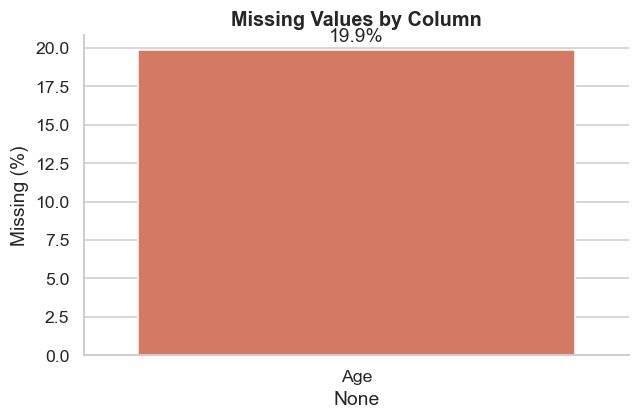

In [19]:
fig, ax = plt.subplots(figsize=(6, 4))
m = miss[miss["missing"] > 0]
sns.barplot(x=m.index, y=m["missing_%"], ax=ax, color="#E76F51")
for c in ax.containers:
    ax.bar_label(c, fmt="{:.1f}%", padding=3)
ax.set_title("Missing Values by Column")
ax.set_ylabel("Missing (%)")
plt.tight_layout()
plt.show()

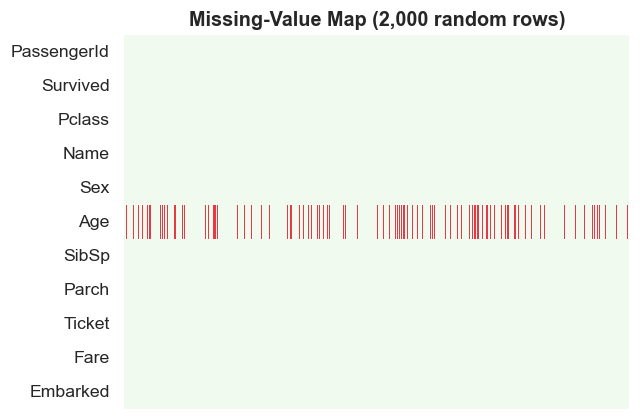

In [20]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(df.isna().sample(2000, random_state=1).T, cbar=False,
            cmap=["#F1FAEE", "#E63946"], ax=ax)
ax.set_title("Missing-Value Map (2,000 random rows)")
ax.set_xticks([])
plt.tight_layout()
plt.show()

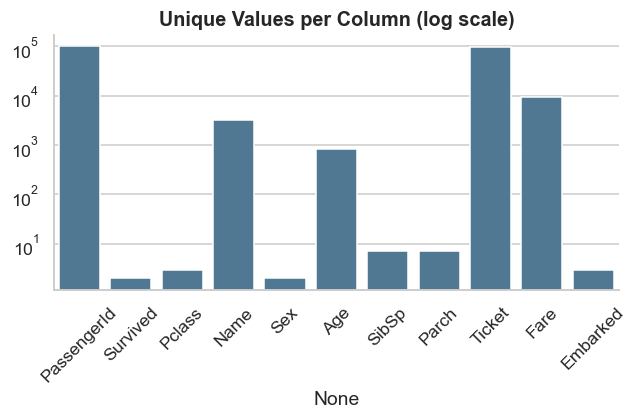

In [21]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=df.nunique().index, y=df.nunique().values, ax=ax, color="#457B9D")
ax.set_yscale("log")
ax.set_title("Unique Values per Column (log scale)")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

In [22]:
def banner(title: str):
    print("\n" + "="*78 + f"\n  {title}\n" + "="*78)
    
banner("4. CLEANING & FEATURE ENGINEERING")
d = df.copy()
d["Outcome"] = d["Survived"].map({0: "Died", 1: "Survived"})
print(f"Shape: {d.shape}")


  4. CLEANING & FEATURE ENGINEERING
Shape: (100000, 12)


In [23]:
d["Title"] = d["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
print("  --- Raw titles ---")
print(d["Title"].value_counts().to_string())

title_map = {"Mr": "Mr", "Mrs": "Mrs", "Miss": "Miss", "Ms": "Miss", "Master": "Master"}
d["TitleGroup"] = d["Title"].map(title_map).fillna("Rare")
print("\n--- TitleGroup ---")
print(d["TitleGroup"].value_counts().to_string())

  --- Raw titles ---
Title
Dr        24797
Rev       15113
Master    15040
Mr        15040
Mrs       10090
Miss       9961
Ms         9959

--- TitleGroup ---
TitleGroup
Rare      39910
Miss      19920
Master    15040
Mr        15040
Mrs       10090


In [24]:
d["AgeMissing"] = d["Age"].isna().astype(int)
d["Age"] = d.groupby(["Pclass", "TitleGroup"])["Age"].transform(
    lambda s: s.fillna(s.median()))
d["Age"] = d["Age"].fillna(d["Age"].median())
print(f"Age imputed for {d['AgeMissing'].sum():,} passengers")
print(f"Missing now: {d['Age'].isna().sum()}")

Age imputed for 19,856 passengers
Missing now: 0


In [25]:
d["FamilySize"] = d["SibSp"] + d["Parch"] + 1
d["IsAlone"] = (d["FamilySize"] == 1).astype(int)
d["FamilyType"] = pd.cut(d["FamilySize"], bins=[0, 1, 4, 20],
                         labels=["Alone", "Small (2-4)", "Large (5+)"])
print(d[["SibSp","Parch","FamilySize","IsAlone","FamilyType"]].head().to_string(index=False))

 SibSp  Parch  FamilySize  IsAlone  FamilyType
     2      3           6        0  Large (5+)
     1      0           2        0 Small (2-4)
     0      0           1        1       Alone
     0      0           1        1       Alone
     0      1           2        0 Small (2-4)


In [26]:
d["AgeGroup"] = pd.cut(d["Age"], bins=[0, 12, 18, 30, 45, 60, 100],
    labels=["Child (0-12)", "Teen (13-18)", "Young Adult (19-30)",
            "Adult (31-45)", "Middle Age (46-60)", "Senior (60+)"])
d["FareBand"] = pd.qcut(d["Fare"].rank(method="first"), 5,
                        labels=["Very Low", "Low", "Medium", "High", "Very High"])
d["LogFare"] = np.log1p(d["Fare"])
d["FarePerPerson"] = d["Fare"] / d["FamilySize"]
print(d[["Age","AgeGroup","Fare","FareBand","LogFare"]].head().to_string(index=False))

 Age           AgeGroup  Fare  FareBand  LogFare
55.6 Middle Age (46-60)  3.02  Very Low 1.391282
85.0       Senior (60+)  8.68    Medium 2.270062
30.6      Adult (31-45)  4.61       Low 1.724551
13.3       Teen (13-18)  5.56       Low 1.880991
55.9 Middle Age (46-60) 40.64 Very High 3.729061


In [27]:
d["ClassLabel"] = d["Pclass"].map({1: "1st Class", 2: "2nd Class", 3: "3rd Class"})
d["PortLabel"] = d["Embarked"].map({"S": "Southampton", "C": "Cherbourg", "Q": "Queenstown"})
d["Surname"] = d["Name"].str.split(",").str[0]
print(d[["Pclass","ClassLabel","Embarked","PortLabel","Surname"]].head().to_string(index=False))

 Pclass ClassLabel Embarked   PortLabel  Surname
      3  3rd Class        Q  Queenstown Robinson
      2  2nd Class        S Southampton   Wilson
      2  2nd Class        S Southampton   Taylor
      3  3rd Class        S Southampton    Smith
      1  1st Class        S Southampton  Jackson


In [28]:
new_cols = ["Outcome", "Title", "TitleGroup", "AgeMissing", "FamilySize",
            "IsAlone", "FamilyType", "AgeGroup", "FareBand", "LogFare",
            "FarePerPerson", "ClassLabel", "PortLabel", "Surname"]
print(f"New features created ({len(new_cols)}): {new_cols}")
print(f"Final shape: {d.shape}")
# df ku mela eluthu
df = d

New features created (14): ['Outcome', 'Title', 'TitleGroup', 'AgeMissing', 'FamilySize', 'IsAlone', 'FamilyType', 'AgeGroup', 'FareBand', 'LogFare', 'FarePerPerson', 'ClassLabel', 'PortLabel', 'Surname']
Final shape: (100000, 25)


In [29]:
def banner(title: str):
    print("\n" + "="*78 + f"\n  {title}\n" + "="*78)

banner("5. DESCRIPTIVE STATISTICS")
num_cols = ["Age", "Fare", "SibSp", "Parch", "FamilySize"]
desc = d[num_cols].describe().T
desc["skew"] = d[num_cols].skew()
desc["kurtosis"] = d[num_cols].kurt()
print("  --- Numeric summary ---")
print(desc.round(2).to_string())


  5. DESCRIPTIVE STATISTICS
  --- Numeric summary ---
               count   mean    std  min    25%   50%    75%     max  skew  kurtosis
Age         100000.0  31.55  17.00  0.4  20.50  30.7  40.60   85.00  0.51      0.32
Fare        100000.0  16.44  23.82  0.0   3.97   7.5  17.95  348.91  3.59     18.29
SibSp       100000.0   0.60   0.78  0.0   0.00   0.0   1.00    6.00  1.30      1.71
Parch       100000.0   0.40   0.63  0.0   0.00   0.0   1.00    6.00  1.60      2.70
FamilySize  100000.0   2.00   1.00  1.0   1.00   2.0   3.00    9.00  1.01      1.03


In [30]:
print("\n  --- Overall survival rate ---")
print(f"  {d['Survived'].mean() * 100:.2f}% survived "
      f"({d['Survived'].sum():,} of {len(d):,})")


  --- Overall survival rate ---
  39.62% survived (39,619 of 100,000)


In [31]:
for col in ["ClassLabel", "Sex", "PortLabel", "TitleGroup", "AgeGroup", "FamilyType", "FareBand"]:
    g = d.groupby(col, observed=True)["Survived"].agg(
        Passengers="count", Survivors="sum", SurvivalRate="mean")
    g["SurvivalRate"] = (g["SurvivalRate"] * 100).round(2)
    print(f"\n  --- Survival by {col} ---")
    print(g.to_string())
    print("\n" + "-"*40)


  --- Survival by ClassLabel ---
            Passengers  Survivors  SurvivalRate
ClassLabel                                     
1st Class        19961      10803         54.12
2nd Class        25132      10075         40.09
3rd Class        54907      18741         34.13

----------------------------------------

  --- Survival by Sex ---
        Passengers  Survivors  SurvivalRate
Sex                                        
female       39793      21835         54.87
male         60207      17784         29.54

----------------------------------------

  --- Survival by PortLabel ---
             Passengers  Survivors  SurvivalRate
PortLabel                                       
Cherbourg          9985       3985         39.91
Queenstown         9887       3913         39.58
Southampton       80128      31721         39.59

----------------------------------------

  --- Survival by TitleGroup ---
            Passengers  Survivors  SurvivalRate
TitleGroup                           

In [32]:
print("\n  --- Average fare & age by class and sex ---")
print(d.pivot_table(index="ClassLabel", columns="Sex",
                    values=["Fare", "Age"], aggfunc="mean").round(2).to_string())


  --- Average fare & age by class and sex ---
              Age          Fare       
Sex        female   male female   male
ClassLabel                            
1st Class   31.82  31.55  48.84  49.86
2nd Class   31.48  31.90  13.97  13.96
3rd Class   31.31  31.50   5.53   5.59


In [33]:
PALETTE = {"Died": "#E63946", "Survived": "#2A9D8F"}
CLASS_COLORS = {"1st Class": "#E9C46A", "2nd Class": "#F4A261", "3rd Class": "#E76F51"}

def save_fig(fig, name, out):
    out.mkdir(parents=True, exist_ok=True)
    fig.tight_layout()
    fig.savefig(out / f"{name}.png", dpi=150)
    print(f"Saved -> {name}.png")
    plt.show()
    plt.close(fig)

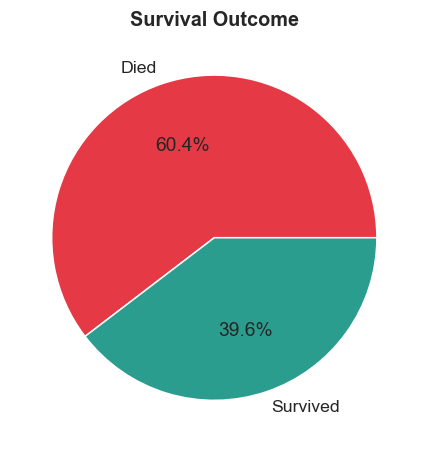

In [34]:
# 1. Survived pie
fig, ax = plt.subplots()
counts = d["Outcome"].value_counts()
ax.pie(counts, labels=counts.index, autopct="%1.1f%%", colors=[PALETTE[i] for i in counts.index])
ax.set_title("Survival Outcome")
plt.show()

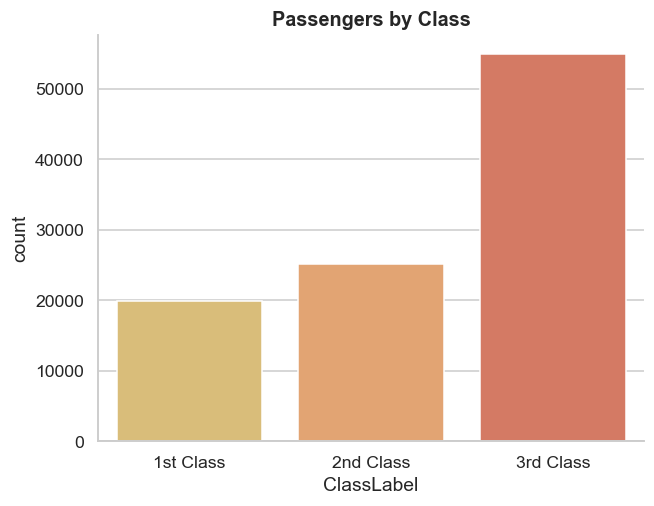

In [35]:
# 2. Class
fig, ax = plt.subplots()
order = ["1st Class", "2nd Class", "3rd Class"]
sns.countplot(data=d, x="ClassLabel", order=order, palette=CLASS_COLORS, ax=ax)
ax.set_title("Passengers by Class")
plt.show()

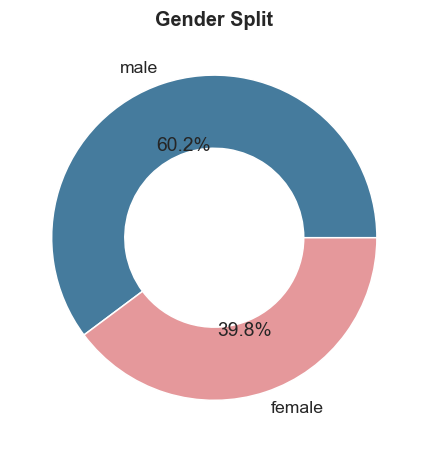

In [36]:
# 3. Gender
fig, ax = plt.subplots()
sx = d["Sex"].value_counts()
ax.pie(sx, labels=sx.index, autopct="%1.1f%%", colors=["#457B9D", "#E5989B"], wedgeprops={"width":0.45})
ax.set_title("Gender Split")
plt.show()

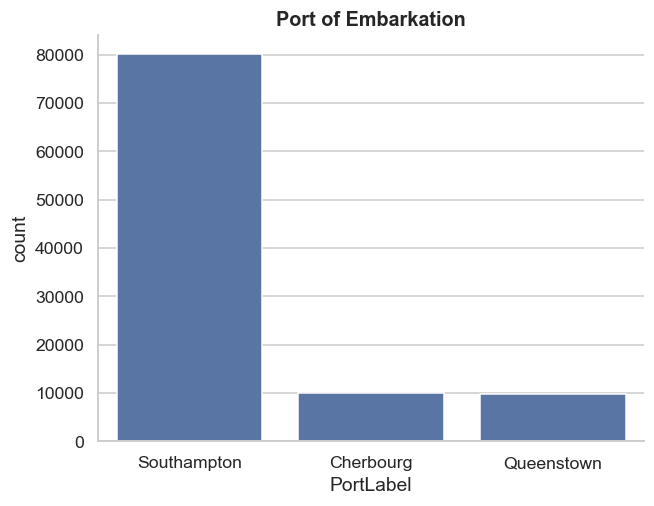

In [37]:
# 4. Port
fig, ax = plt.subplots()
sns.countplot(data=d, x="PortLabel", order=d["PortLabel"].value_counts().index, ax=ax)
ax.set_title("Port of Embarkation")
plt.show()

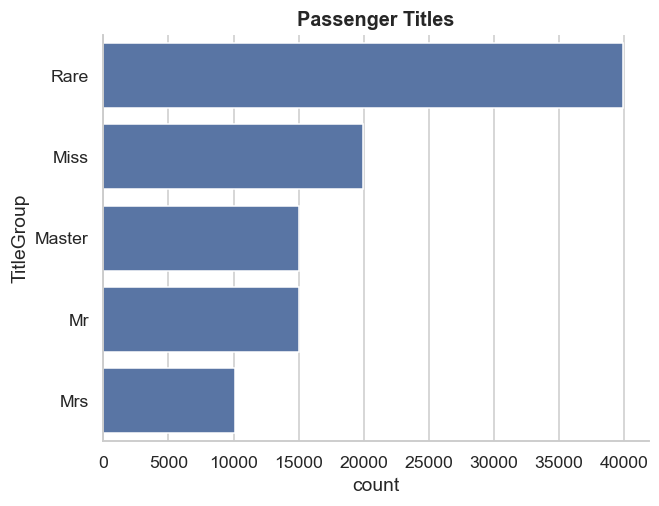

In [38]:
# 5. TitleGroup
fig, ax = plt.subplots()
sns.countplot(data=d, y="TitleGroup", order=d["TitleGroup"].value_counts().index, ax=ax)
ax.set_title("Passenger Titles")
plt.show()

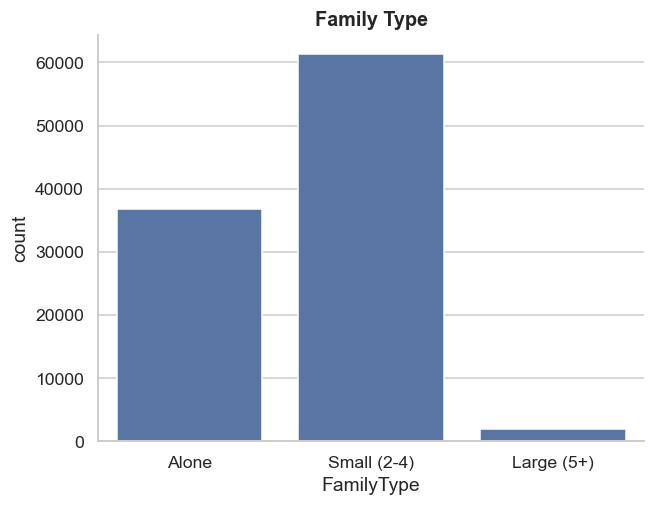

In [39]:
# 6. FamilyType
fig, ax = plt.subplots()
sns.countplot(data=d, x="FamilyType", ax=ax)
ax.set_title("Family Type")
plt.show()

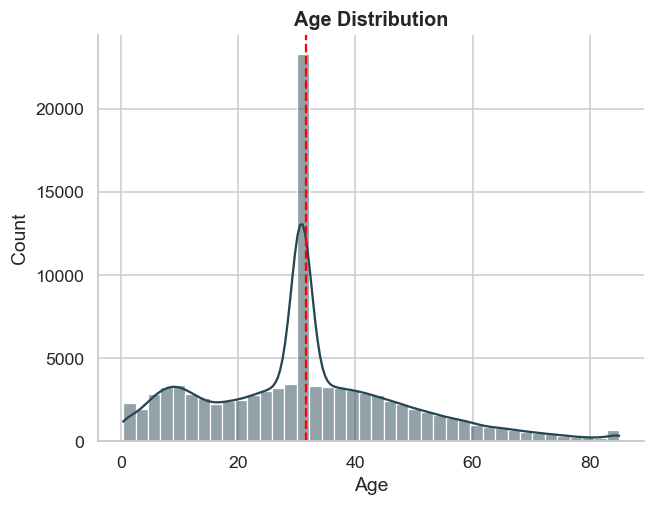

In [40]:
fig, ax = plt.subplots()
sns.histplot(d["Age"], bins=40, kde=True, color="#264653", ax=ax)
ax.axvline(d["Age"].mean(), color="red", ls="--")
ax.set_title("Age Distribution")
plt.show()

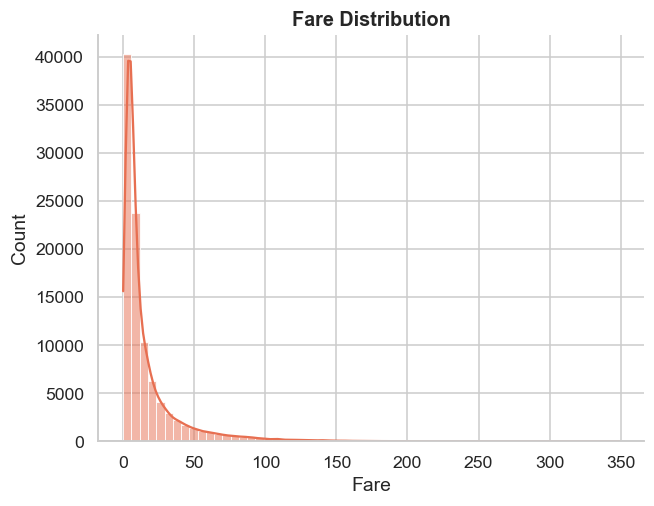

In [41]:
fig, ax = plt.subplots()
sns.histplot(d["Fare"], bins=60, kde=True, color="#E76F51", ax=ax)
ax.set_title("Fare Distribution")
plt.show()

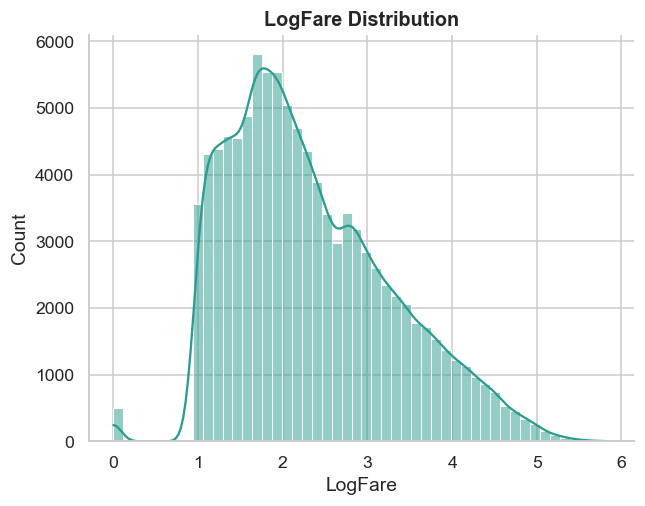

In [42]:
fig, ax = plt.subplots()
sns.histplot(d["LogFare"], bins=50, kde=True, color="#2A9D8F", ax=ax)
ax.set_title("LogFare Distribution")
plt.show()

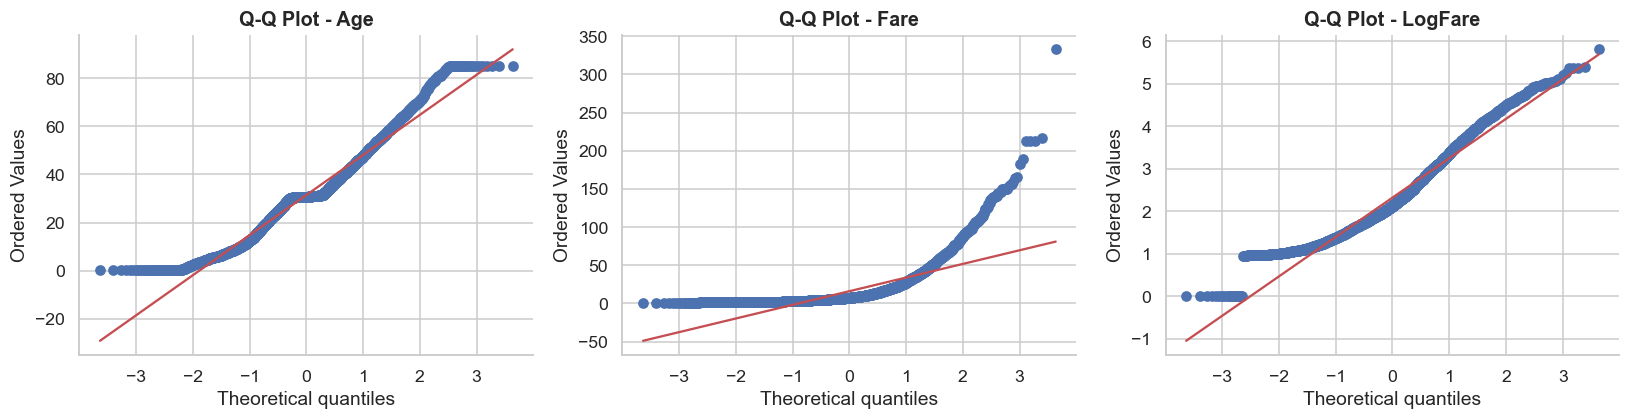

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(15,4))
sample = d.sample(min(5000, len(d)), random_state=42)
for ax, col in zip(axes, ["Age", "Fare", "LogFare"]):
    stats.probplot(sample[col], dist="norm", plot=ax)
    ax.set_title(f"Q-Q Plot - {col}")
plt.tight_layout()
plt.show()

In [44]:
def add_bar_labels(ax, fmt="{:.1f}%"):
    for c in ax.containers:
        ax.bar_label(c, fmt=fmt, padding=3, fontsize=9)

PALETTE = {"Died": "#E63946", "Survived": "#2A9D8F"}
CLASS_COLORS = ["#E9C46A", "#F4A261", "#E76F51"] # list ah maathu

overall = d["Survived"].mean() * 100
print(f"Overall survival: {overall:.1f}%")

Overall survival: 39.6%


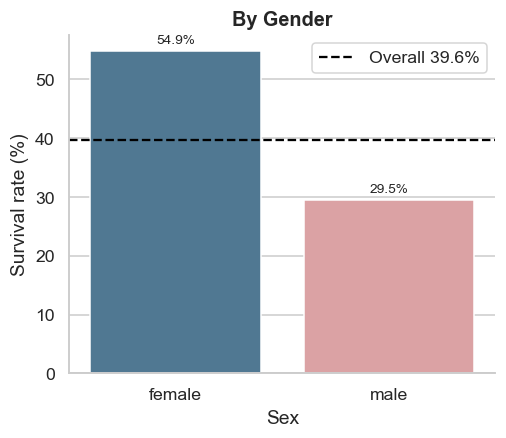

In [45]:
# 1. By Gender
fig, ax = plt.subplots(figsize=(5,4))
g = d.groupby("Sex")["Survived"].mean()*100
sns.barplot(x=g.index, y=g.values, palette=["#457B9D", "#E5989B"], ax=ax)
ax.axhline(overall, color="black", ls="--", label=f"Overall {overall:.1f}%")
add_bar_labels(ax)
ax.set_title("By Gender")
ax.set_ylabel("Survival rate (%)")
ax.legend()
plt.show()

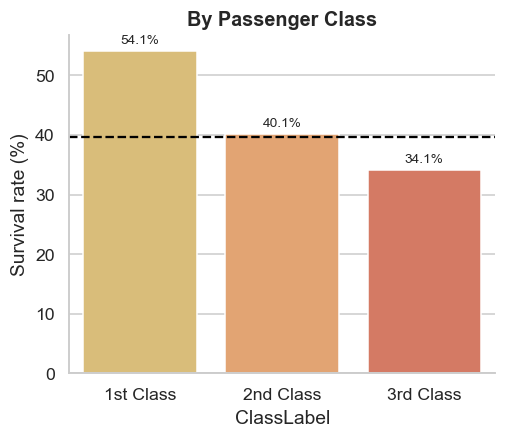

In [46]:
# 2. By Class
fig, ax = plt.subplots(figsize=(5,4))
g = d.groupby("ClassLabel")["Survived"].mean()*100
g = g.reindex(["1st Class", "2nd Class", "3rd Class"])
sns.barplot(x=g.index, y=g.values, palette=CLASS_COLORS, ax=ax)
ax.axhline(overall, color="black", ls="--")
add_bar_labels(ax)
ax.set_title("By Passenger Class")
ax.set_ylabel("Survival rate (%)")
plt.show()

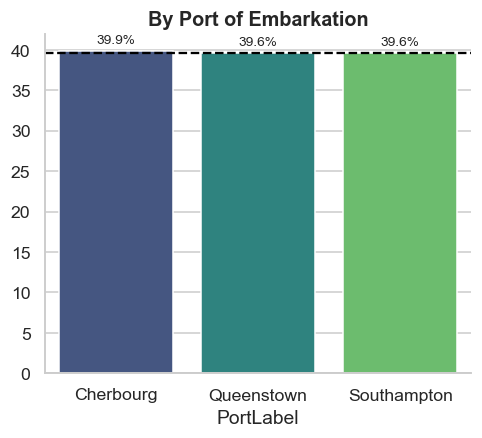

In [47]:
# 3. By Port
fig, ax = plt.subplots(figsize=(5,4))
g = d.groupby("PortLabel")["Survived"].mean()*100
sns.barplot(x=g.index, y=g.values, palette="viridis", ax=ax)
ax.axhline(overall, color="black", ls="--")
add_bar_labels(ax)
ax.set_title("By Port of Embarkation")
plt.show()

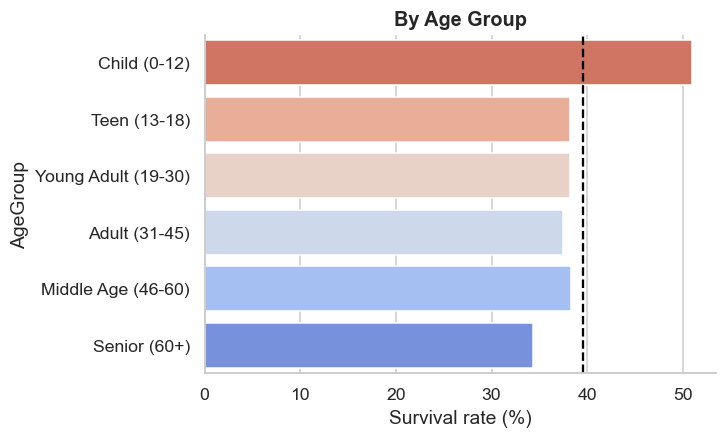

In [48]:
# 4. By AgeGroup - horizontal
fig, ax = plt.subplots(figsize=(6,4))
g = d.groupby("AgeGroup", observed=True)["Survived"].mean()*100
sns.barplot(x=g.values, y=g.index.astype(str), palette="coolwarm_r", ax=ax)
ax.axvline(overall, color="black", ls="--")
ax.set_title("By Age Group")
ax.set_xlabel("Survival rate (%)")
plt.show()

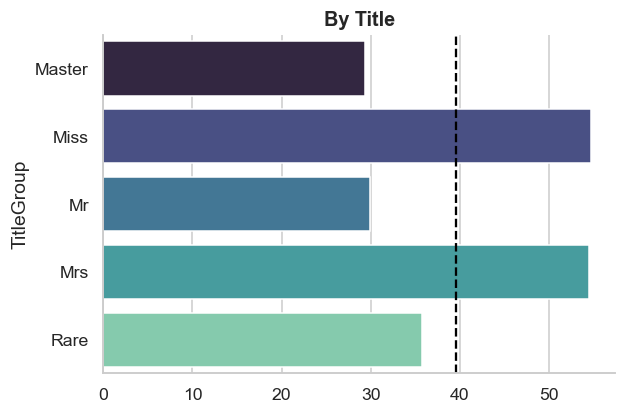

In [50]:
# 5. By Title
fig, ax = plt.subplots(figsize=(6,4))
g = d.groupby("TitleGroup")["Survived"].mean()*100
sns.barplot(x=g.values, y=g.index, palette="mako", ax=ax)
ax.axvline(overall, color="black", ls="--")
ax.set_title("By Title")
plt.show()

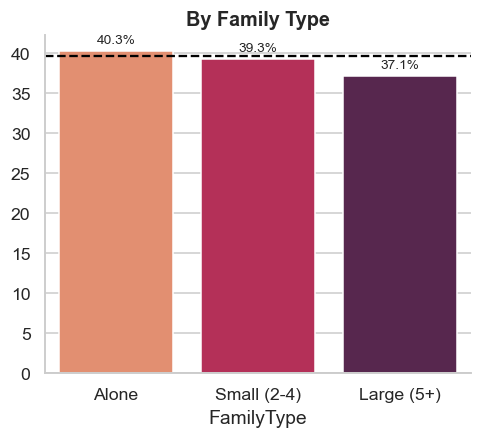

In [52]:
# 6. By FamilyType
fig, ax = plt.subplots(figsize=(5,4))
g = d.groupby("FamilyType")["Survived"].mean()*100
sns.barplot(x=g.index, y=g.values, palette="rocket_r", ax=ax)
ax.axhline(overall, color="black", ls="--")
add_bar_labels(ax)
ax.set_title("By Family Type")
plt.show()

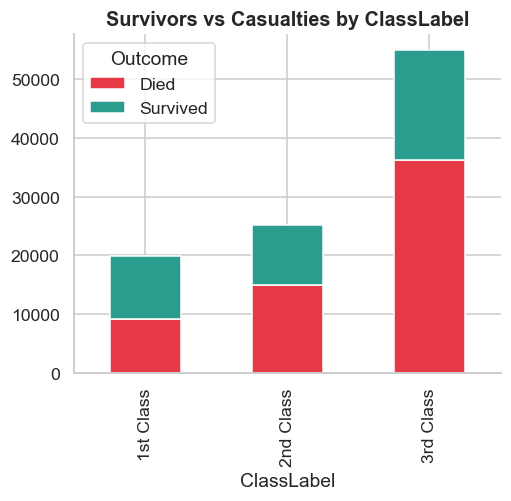

In [53]:
import matplotlib.ticker as mtick

col = "ClassLabel"
fig, ax = plt.subplots(figsize=(5,4))
ct = pd.crosstab(d[col], d["Outcome"])[["Died", "Survived"]]
ct.plot(kind="bar", stacked=True, ax=ax, color=[PALETTE["Died"], PALETTE["Survived"]])
ax.set_title(f"Survivors vs Casualties by {col}")
plt.show()

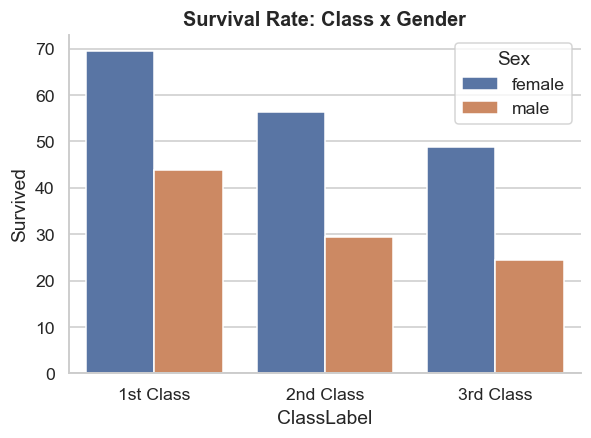

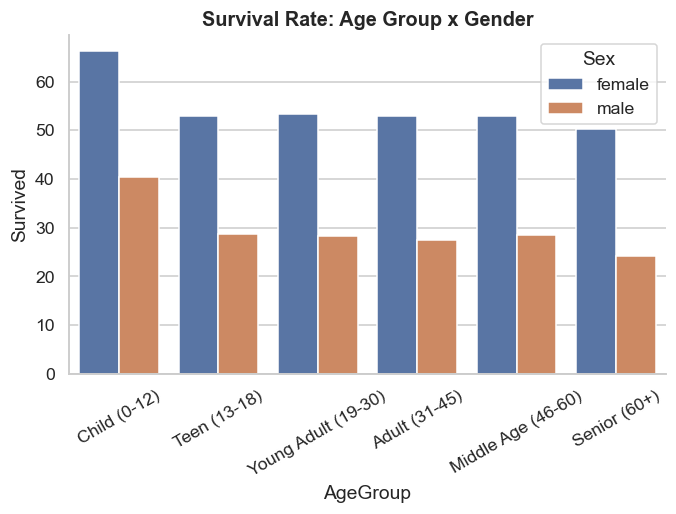

In [54]:
# Class x Sex
fig, ax = plt.subplots(figsize=(6,4))
g = (d.groupby(["ClassLabel", "Sex"])["Survived"].mean()*100).reset_index()
sns.barplot(data=g, x="ClassLabel", y="Survived", hue="Sex", ax=ax)
ax.set_title("Survival Rate: Class x Gender")
plt.show()

# AgeGroup x Sex
fig, ax = plt.subplots(figsize=(7,4))
g2 = (d.groupby(["AgeGroup", "Sex"], observed=True)["Survived"].mean()*100).reset_index()
sns.barplot(data=g2, x="AgeGroup", y="Survived", hue="Sex", ax=ax)
ax.set_title("Survival Rate: Age Group x Gender")
ax.tick_params(axis="x", rotation=30)
plt.show()

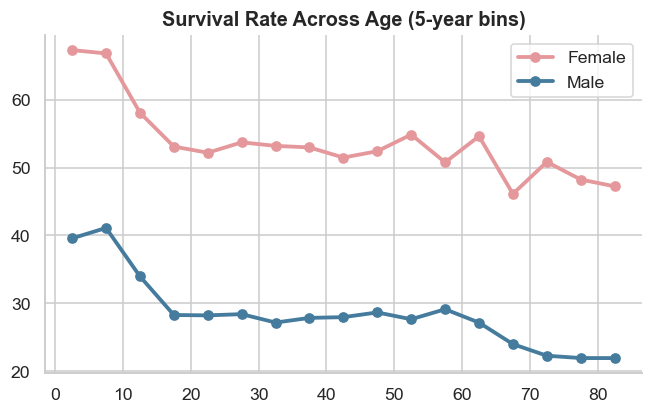

In [55]:
bins = np.arange(0, 90, 5)
d_tmp = d.assign(AgeBin=pd.cut(d["Age"], bins, include_lowest=True))

fig, ax = plt.subplots(figsize=(7,4))
for sex, color in [("female", "#E5989B"), ("male", "#457B9D")]:
    s = d_tmp[d_tmp["Sex"]==sex].groupby("AgeBin", observed=True)["Survived"].mean()*100
    mids = [iv.mid for iv in s.index]
    ax.plot(mids, s.values, marker="o", lw=2.5, color=color, label=sex.title())
ax.set_title("Survival Rate Across Age (5-year bins)")
ax.legend()
plt.show()

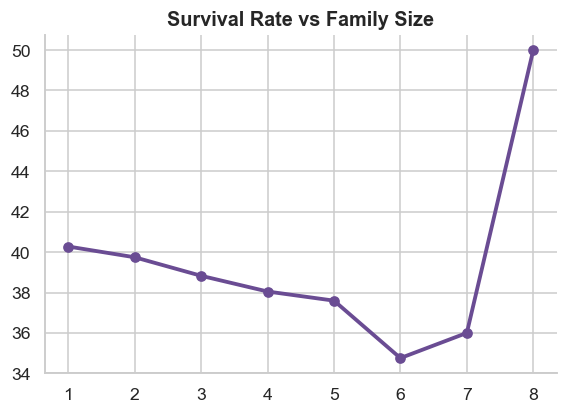

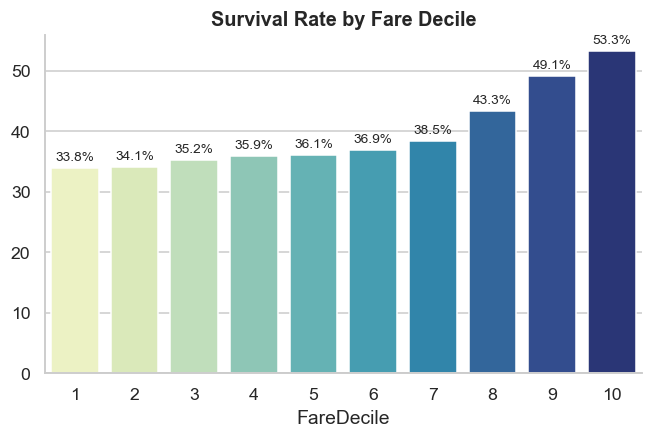

In [56]:
# Family Size
fig, ax = plt.subplots(figsize=(6,4))
fam = d.groupby("FamilySize")["Survived"].agg(["mean", "count"])
fam = fam[fam["count"]>=10]
ax.plot(fam.index, fam["mean"]*100, marker="o", lw=2.5, color="#6A4C93")
ax.set_title("Survival Rate vs Family Size")
plt.show()

# Fare Decile
fig, ax = plt.subplots(figsize=(7,4))
fare_q = d.assign(FareDecile=pd.qcut(d["Fare"].rank(method="first"), 10, labels=range(1,11)))
fd = fare_q.groupby("FareDecile", observed=True)["Survived"].mean()*100
sns.barplot(x=fd.index.astype(str), y=fd.values, palette="YlGnBu", ax=ax)
add_bar_labels(ax)
ax.set_title("Survival Rate by Fare Decile")
plt.show()

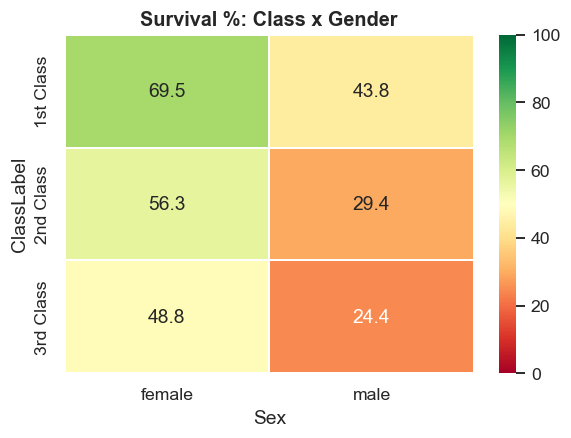

In [57]:
# 10a Class x Gender
fig, ax = plt.subplots(figsize=(6,4))
p1 = d.pivot_table(index="ClassLabel", columns="Sex", values="Survived", aggfunc="mean")*100
sns.heatmap(p1, annot=True, fmt=".1f", cmap="RdYlGn", vmin=0, vmax=100, linewidths=1, ax=ax)
ax.set_title("Survival %: Class x Gender")
plt.show()

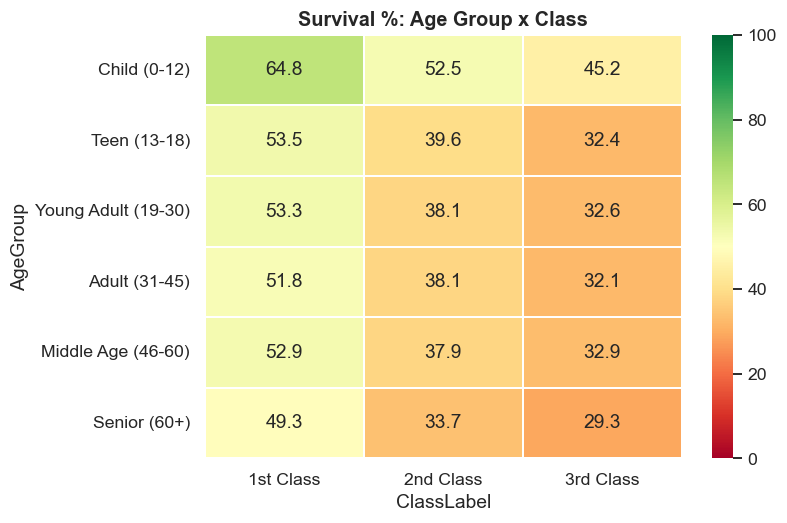

In [58]:
# 10b AgeGroup x Class
fig, ax = plt.subplots(figsize=(7,5))
p2 = d.pivot_table(index="AgeGroup", columns="ClassLabel", values="Survived", aggfunc="mean", observed=True)*100
sns.heatmap(p2, annot=True, fmt=".1f", cmap="RdYlGn", vmin=0, vmax=100, linewidths=1, ax=ax)
ax.set_title("Survival %: Age Group x Class")
plt.show()

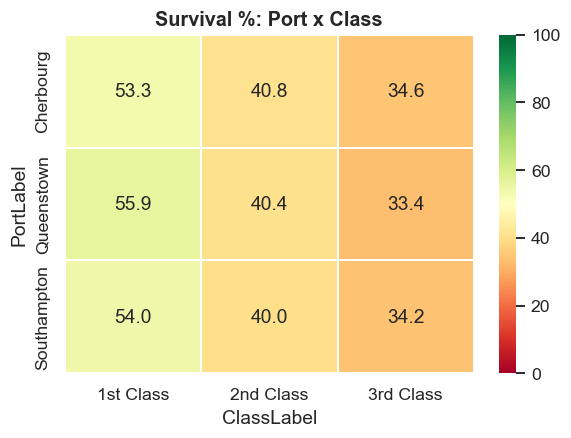

In [59]:
# 10c Port x Class
fig, ax = plt.subplots(figsize=(6,4))
p3 = d.pivot_table(index="PortLabel", columns="ClassLabel", values="Survived", aggfunc="mean")*100
sns.heatmap(p3, annot=True, fmt=".1f", cmap="RdYlGn", vmin=0, vmax=100, linewidths=1, ax=ax)
ax.set_title("Survival %: Port x Class")
plt.show()

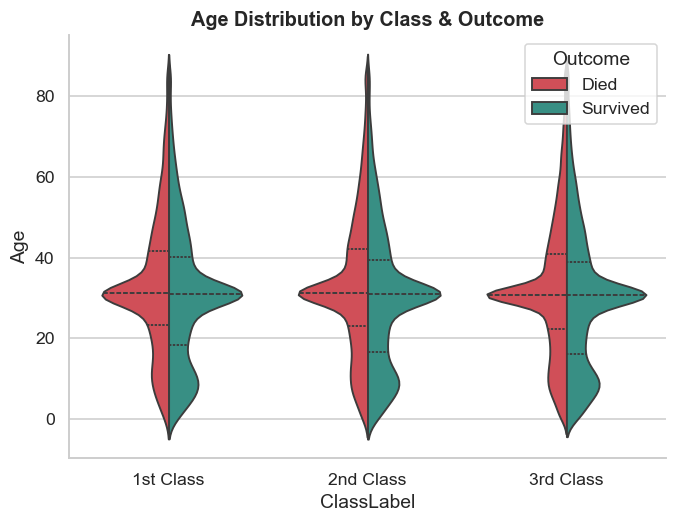

In [60]:
fig, ax = plt.subplots(figsize=(7,5))
sns.violinplot(data=d, x="ClassLabel", y="Age", hue="Outcome", split=True, order=["1st Class","2nd Class","3rd Class"], palette=PALETTE, inner="quartile", ax=ax)
ax.set_title("Age Distribution by Class & Outcome")
plt.show()

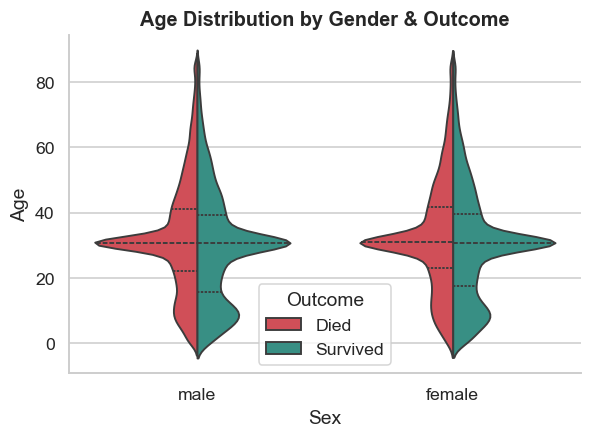

In [61]:
fig, ax = plt.subplots(figsize=(6,4))
sns.violinplot(data=d, x="Sex", y="Age", hue="Outcome", split=True, palette=PALETTE, inner="quartile", ax=ax)
ax.set_title("Age Distribution by Gender & Outcome")
plt.show()

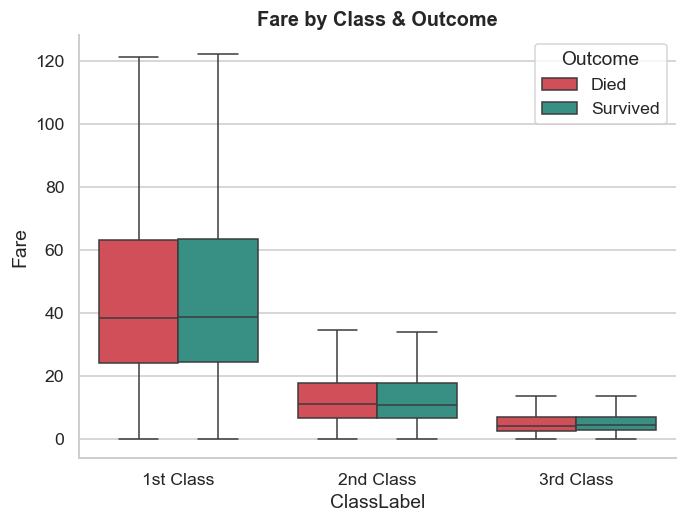

In [62]:
fig, ax = plt.subplots(figsize=(7,5))
sns.boxplot(data=d, x="ClassLabel", y="Fare", hue="Outcome", order=["1st Class","2nd Class","3rd Class"], palette=PALETTE, showfliers=False, ax=ax)
ax.set_title("Fare by Class & Outcome")
plt.show()

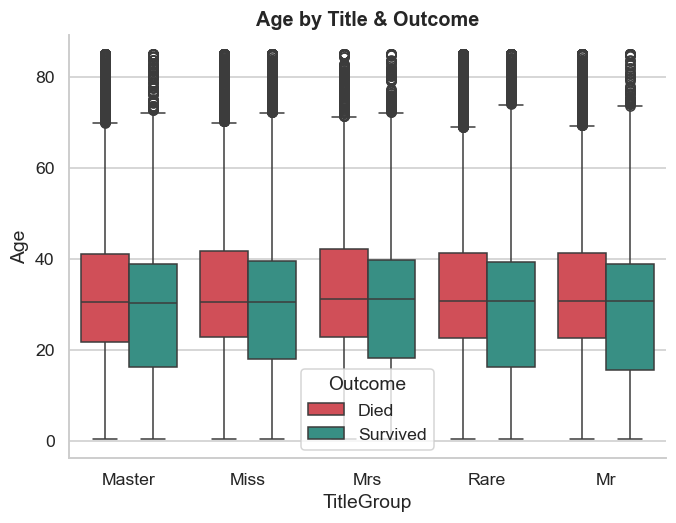

In [63]:
fig, ax = plt.subplots(figsize=(7,5))
sns.boxplot(data=d, x="TitleGroup", y="Age", hue="Outcome", palette=PALETTE, ax=ax)
ax.set_title("Age by Title & Outcome")
plt.show()

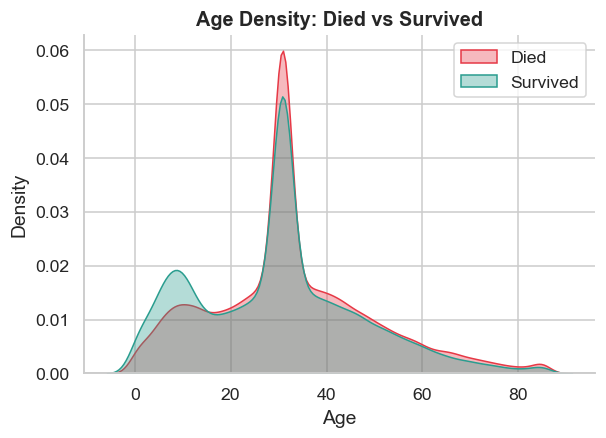

In [64]:
fig, ax = plt.subplots(figsize=(6,4))
for outcome, color in PALETTE.items():
    sub = d[d["Outcome"]==outcome]
    sns.kdeplot(sub["Age"], fill=True, alpha=0.35, color=color, label=outcome, ax=ax)
ax.set_title("Age Density: Died vs Survived")
ax.legend()
plt.show()

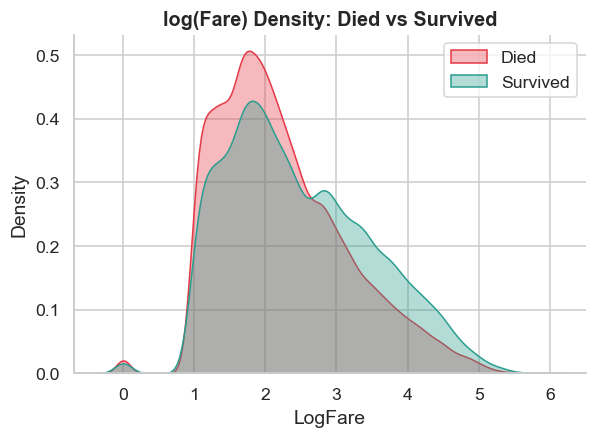

In [65]:
fig, ax = plt.subplots(figsize=(6,4))
for outcome, color in PALETTE.items():
    sub = d[d["Outcome"]==outcome]
    sns.kdeplot(sub["LogFare"], fill=True, alpha=0.35, color=color, label=outcome, ax=ax)
ax.set_title("log(Fare) Density: Died vs Survived")
ax.legend()
plt.show()

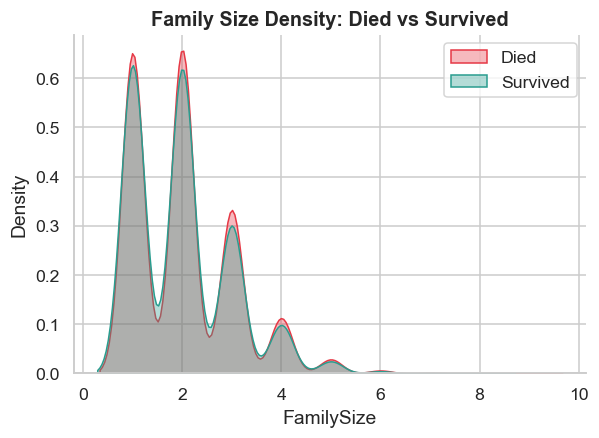

In [66]:
fig, ax = plt.subplots(figsize=(6,4))
for outcome, color in PALETTE.items():
    sub = d[d["Outcome"]==outcome]
    sns.kdeplot(sub["FamilySize"], fill=True, alpha=0.35, color=color, label=outcome, ax=ax, bw_adjust=2)
ax.set_title("Family Size Density: Died vs Survived")
ax.legend()
plt.show()

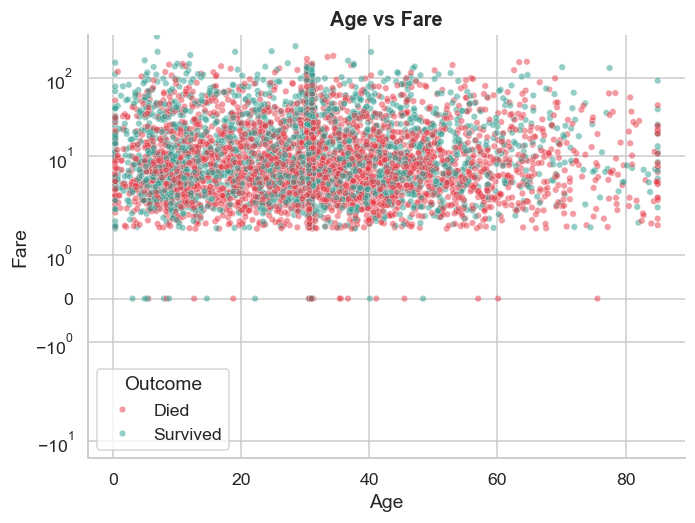

In [67]:
fig, ax = plt.subplots(figsize=(7,5))
samp = d.sample(min(6000, len(d)), random_state=42)
sns.scatterplot(data=samp, x="Age", y="Fare", hue="Outcome", palette=PALETTE, alpha=0.5, s=18, ax=ax)
ax.set_yscale("symlog")
ax.set_title("Age vs Fare")
plt.show()

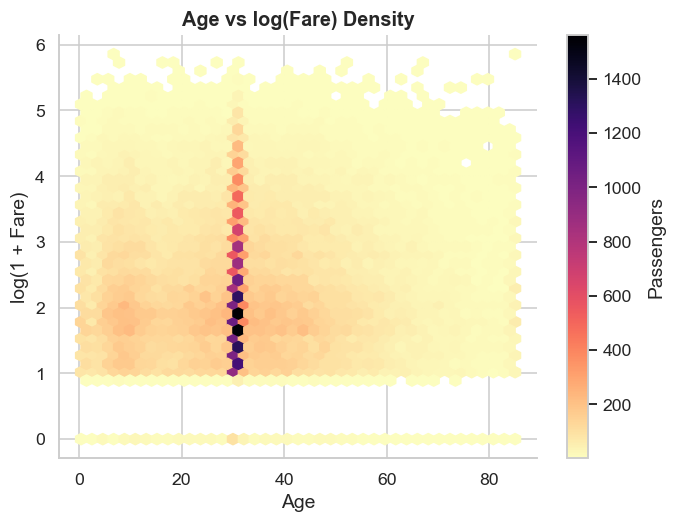

In [68]:
fig, ax = plt.subplots(figsize=(7,5))
hb = ax.hexbin(d["Age"], d["LogFare"], gridsize=40, cmap="magma_r", mincnt=1)
plt.colorbar(hb, ax=ax, label="Passengers")
ax.set_xlabel("Age")
ax.set_ylabel("log(1 + Fare)")
ax.set_title("Age vs log(Fare) Density")
plt.show()

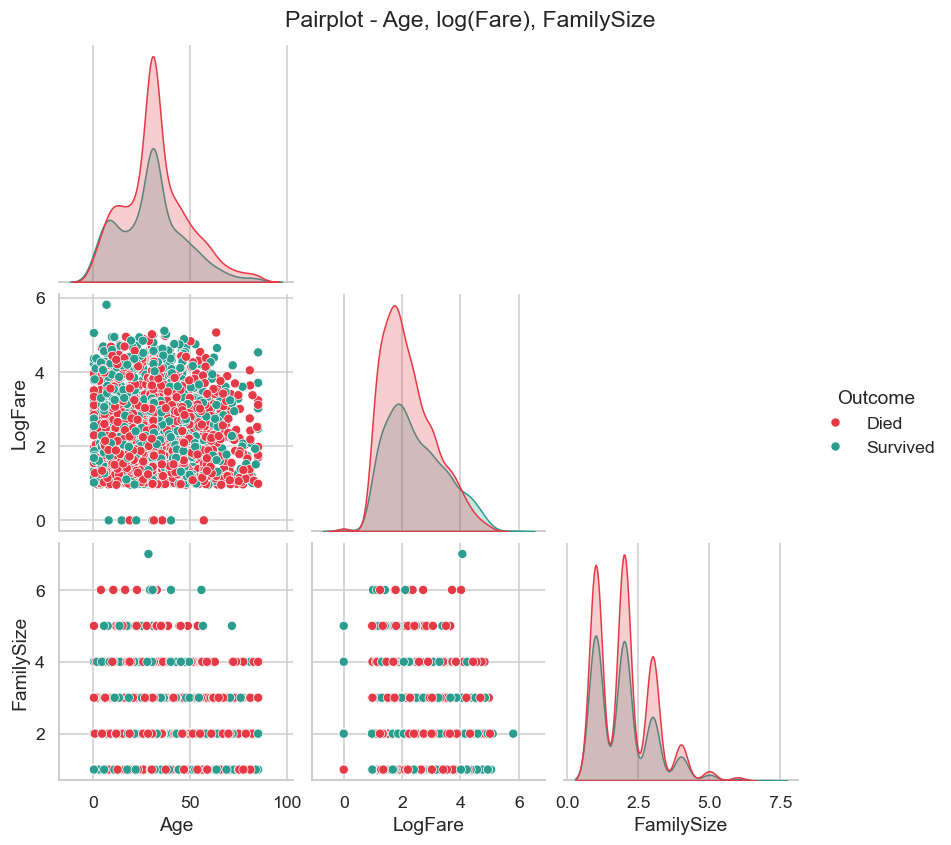

In [69]:
cols = ["Age", "LogFare", "FamilySize", "Outcome"]
pp = sns.pairplot(d.sample(min(3000, len(d)), random_state=42)[cols], hue="Outcome", palette=PALETTE, diag_kind="kde", corner=True)
pp.fig.suptitle("Pairplot - Age, log(Fare), FamilySize", y=1.02)
plt.show()

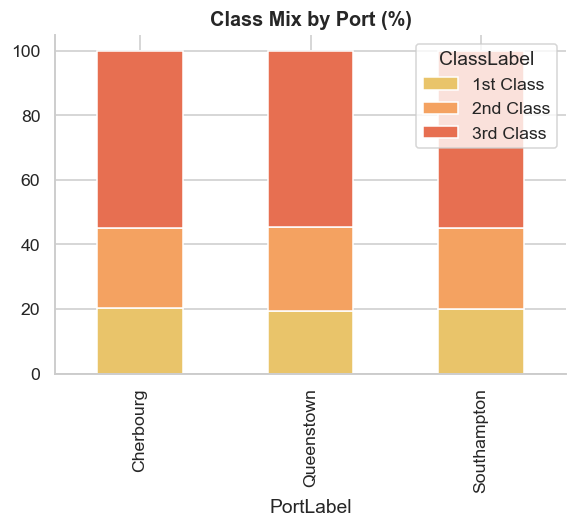

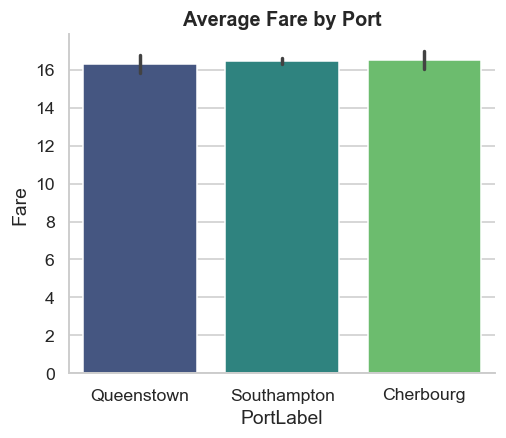

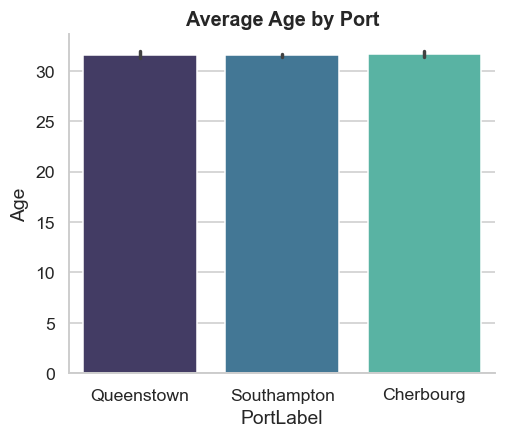

In [72]:
# Class mix
fig, ax = plt.subplots(figsize=(6,4))
ct = pd.crosstab(d["PortLabel"], d["ClassLabel"], normalize="index")*100
ct[["1st Class","2nd Class","3rd Class"]].plot(kind="bar", stacked=True, ax=ax, color=CLASS_COLORS)
ax.set_title("Class Mix by Port (%)")
plt.show()

# Avg Fare by port
fig, ax = plt.subplots(figsize=(5,4))
sns.barplot(data=d, x="PortLabel", y="Fare", palette="viridis", ax=ax)
ax.set_title("Average Fare by Port")
plt.show()

# Avg Age by port
fig, ax = plt.subplots(figsize=(5,4))
sns.barplot(data=d, x="PortLabel", y="Age", palette="mako", ax=ax)
ax.set_title("Average Age by Port")
plt.show()

In [73]:
corr_df = d[["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare", "LogFare",
             "FamilySize", "IsAlone", "FarePerPerson"]].copy()
corr_df["Sex_female"] = (d["Sex"] == "female").astype(int)
corr_df["Embarked_C"] = (d["Embarked"] == "C").astype(int)

pear = corr_df.corr(method="pearson")
spear = corr_df.corr(method="spearman")

target_corr = pear["Survived"].drop("Survived").sort_values()
print("  --- Pearson correlation with Survived ---")
print(target_corr.round(4).to_string())

  --- Pearson correlation with Survived ---
Pclass          -0.1526
Age             -0.0721
SibSp           -0.0336
FamilySize      -0.0151
Embarked_C       0.0020
IsAlone          0.0103
Parch            0.0175
FarePerPerson    0.1009
Fare             0.1105
LogFare          0.1248
Sex_female       0.2535


NameError: name 'out' is not defined

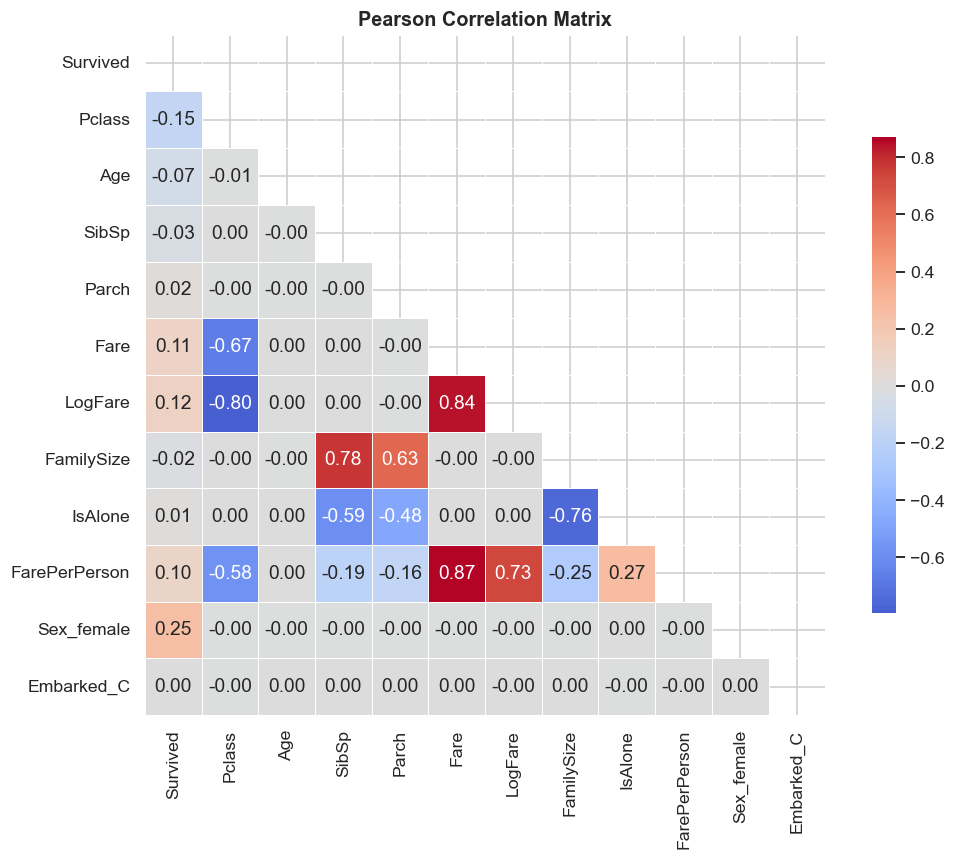

In [74]:
fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(pear, dtype=bool))
sns.heatmap(pear, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            linewidths=0.5, square=True, ax=ax, cbar_kws={"shrink": 0.7})
ax.set_title("Pearson Correlation Matrix")
plt.tight_layout()
plt.savefig(out / "16a_pearson.png", dpi=150)
plt.show()

NameError: name 'out' is not defined

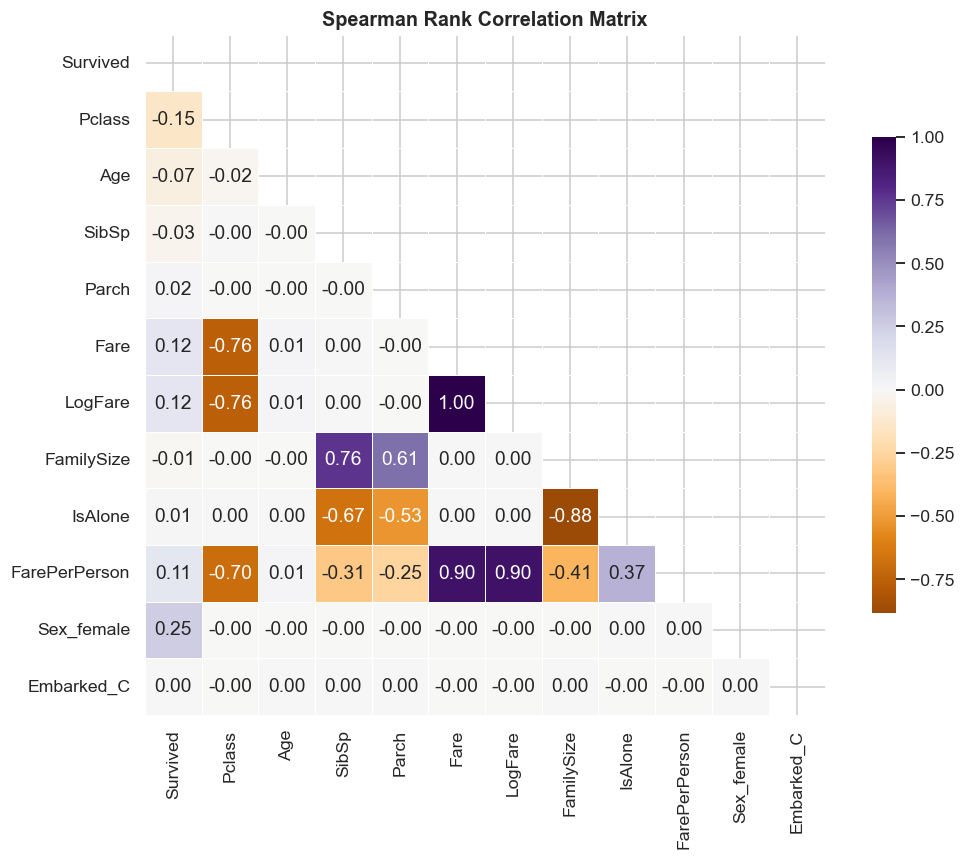

In [75]:
fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(spear, dtype=bool))
sns.heatmap(spear, mask=mask, annot=True, fmt=".2f", cmap="PuOr", center=0,
            linewidths=0.5, square=True, ax=ax, cbar_kws={"shrink": 0.7})
ax.set_title("Spearman Rank Correlation Matrix")
plt.tight_layout()
plt.savefig(out / "16b_spearman.png", dpi=150)
plt.show()

NameError: name 'out' is not defined

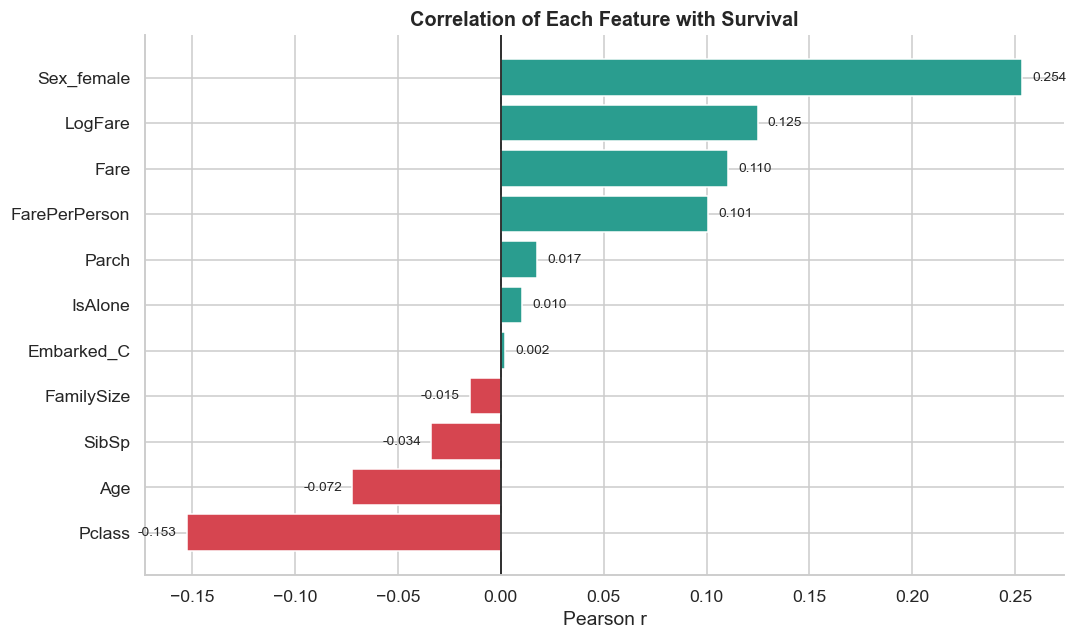

In [76]:
fig, ax = plt.subplots(figsize=(10, 6))
colors = ["#2A9D8F" if v > 0 else "#D64550" for v in target_corr.values]
ax.barh(target_corr.index, target_corr.values, color=colors)
for i, v in enumerate(target_corr.values):
    ax.text(v + (0.005 if v > 0 else -0.005), i, f"{v:.3f}",
            va="center", ha="left" if v > 0 else "right", fontsize=9)
ax.axvline(0, color="black", lw=1)
ax.set_title("Correlation of Each Feature with Survival")
ax.set_xlabel("Pearson r")
plt.tight_layout()
plt.savefig(out / "17_target_correlation_bar.png", dpi=150)
plt.show()

In [77]:
def cramers_v(x, y):
    import numpy as np
    from scipy import stats
    confusion = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(confusion)[0]
    n = confusion.sum().sum()
    phi2 = chi2/n
    r,k = confusion.shape
    return np.sqrt(phi2 / min(k-1, r-1))

from scipy import stats
import numpy as np

In [78]:
rows = []
for col in ["Sex", "Pclass", "Embarked", "TitleGroup", "AgeGroup", "FamilyType", "IsAlone"]:
    table = pd.crosstab(d[col], d["Survived"])
    chi2, p, dof, _ = stats.chi2_contingency(table)
    v = cramers_v(d[col], d["Survived"])
    rows.append({"Test": "Chi-square", "Variable": col, "Statistic": chi2, "p_value": p, "Effect size": v, "Effect metric": "Cramer's V"})
    print(f"{col}: chi2={chi2:.2f}, p={p:.2e}, V={v:.3f} -> Significant")

Sex: chi2=6426.35, p=0.00e+00, V=0.254 -> Significant
Pclass: chi2=2447.99, p=0.00e+00, V=0.156 -> Significant
Embarked: chi2=0.39, p=8.22e-01, V=0.002 -> Significant
TitleGroup: chi2=4312.77, p=0.00e+00, V=0.208 -> Significant
AgeGroup: chi2=1000.39, p=4.96e-214, V=0.100 -> Significant
FamilyType: chi2=14.11, p=8.61e-04, V=0.012 -> Significant
IsAlone: chi2=10.48, p=1.21e-03, V=0.010 -> Significant


In [79]:
for col in ["Age", "Fare", "FamilySize"]:
    a = d.loc[d["Survived"] == 1, col]
    b = d.loc[d["Survived"] == 0, col]
    t, p_t = stats.ttest_ind(a, b, equal_var=False)
    pooled = np.sqrt((a.var() + b.var()) / 2)
    cohen = (a.mean() - b.mean()) / pooled
    print(f"{col} t-test: t={t:.2f}, p={p_t:.2e}, Cohen d={cohen:.3f}")
    
    u, p_u = stats.mannwhitneyu(a, b, alternative="two-sided")
    rb = 1 - (2 * u) / (len(a) * len(b))
    print(f"{col} MWU: U={u:.0f}, p={p_u:.2e}, r={rb:.3f}\n")
    
    rows.append({"Test": "Welch t-test", "Variable": col, "Statistic": t, "p_value": p_t, "Effect size": cohen, "Effect metric": "Cohen's d"})
    rows.append({"Test": "Mann-Whitney U", "Variable": col, "Statistic": u, "p_value": p_u, "Effect size": rb, "Effect metric": "Rank-biserial"})

Age t-test: t=-22.74, p=3.64e-114, Cohen d=-0.147
Age MWU: U=1102115150, p=1.96e-98, r=0.079

Fare t-test: t=33.50, p=3.88e-244, Cohen d=0.222
Fare MWU: U=1361583360, p=1.28e-300, r=-0.138

FamilySize t-test: t=-4.79, p=1.70e-06, Cohen d=-0.031
FamilySize MWU: U=1177307995, p=8.34e-06, r=0.016



In [80]:
# ANOVA
groups = [g["Fare"].values for _, g in d.groupby("Pclass")]
f, p_f = stats.f_oneway(*groups)
rows.append({"Test": "ANOVA", "Variable": "Fare ~ Pclass", "Statistic": f, "p_value": p_f, "Effect size": np.nan, "Effect metric": "-"})
h, p_h = stats.kruskal(*groups)
rows.append({"Test": "Kruskal-Wallis", "Variable": "Fare ~ Pclass", "Statistic": h, "p_value": p_h, "Effect size": np.nan, "Effect metric": "-"})

res = pd.DataFrame(rows)
res["Significant"] = np.where(res["p_value"] < 0.05, "YES", "no")
print(res.to_string(index=False))

print("\n  --- 95% confidence intervals for survival rate ---")
ci_rows = []
for key, g in d.groupby(["ClassLabel", "Sex"]):
    n, k = len(g), g["Survived"].sum()
    p_hat = k / n
    se = np.sqrt(p_hat * (1 - p_hat) / n)
    ci_rows.append((f"{key[0]} / {key[1]}", n, p_hat * 100, (p_hat - 1.96 * se) * 100, (p_hat + 1.96 * se) * 100))
ci = pd.DataFrame(ci_rows, columns=["Group", "n", "rate", "lo", "hi"])
print(ci.round(2).to_string(index=False))

          Test      Variable     Statistic       p_value  Effect size Effect metric Significant
    Chi-square           Sex  6.426346e+03  0.000000e+00     0.253502    Cramer's V         YES
    Chi-square        Pclass  2.447988e+03  0.000000e+00     0.156460    Cramer's V         YES
    Chi-square      Embarked  3.927142e-01  8.217187e-01     0.001982    Cramer's V          no
    Chi-square    TitleGroup  4.312771e+03  0.000000e+00     0.207672    Cramer's V         YES
    Chi-square      AgeGroup  1.000386e+03 4.958175e-214     0.100019    Cramer's V         YES
    Chi-square    FamilyType  1.411470e+01  8.610576e-04     0.011881    Cramer's V         YES
    Chi-square       IsAlone  1.048173e+01  1.205609e-03     0.010238    Cramer's V         YES
  Welch t-test           Age -2.274431e+01 3.644047e-114    -0.147400     Cohen's d         YES
Mann-Whitney U           Age  1.102115e+09  1.964473e-98     0.078589 Rank-biserial         YES
  Welch t-test          Fare  3.350035e+

NameError: name 'out' is not defined

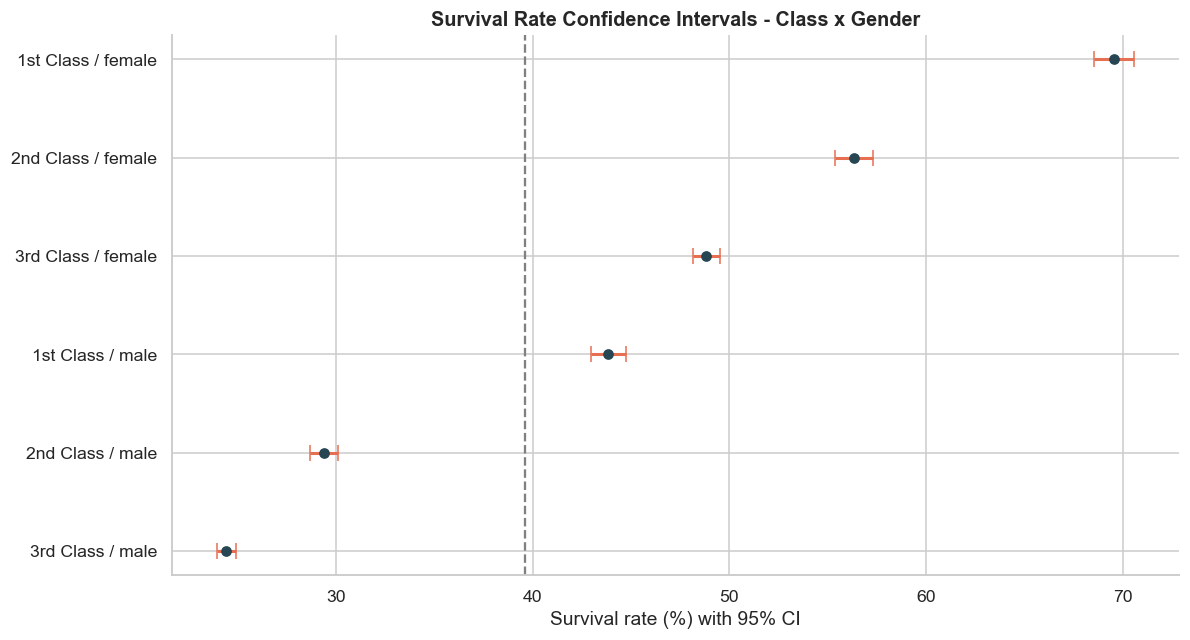

In [81]:
fig, ax = plt.subplots(figsize=(11, 6))
ci = ci.sort_values("rate")
ax.errorbar(ci["rate"], range(len(ci)), xerr=[ci["rate"] - ci["lo"], ci["hi"] - ci["rate"]], fmt="o", color="#264653", ecolor="#E76F51", capsize=5, lw=2)
ax.set_yticks(range(len(ci)))
ax.set_yticklabels(ci["Group"])
ax.axvline(d["Survived"].mean() * 100, color="gray", ls="--")
ax.set_xlabel("Survival rate (%) with 95% CI")
ax.set_title("Survival Rate Confidence Intervals - Class x Gender")
plt.tight_layout()
plt.savefig(out / "18_confidence_intervals.png", dpi=150)
plt.show()

NameError: name 'out' is not defined

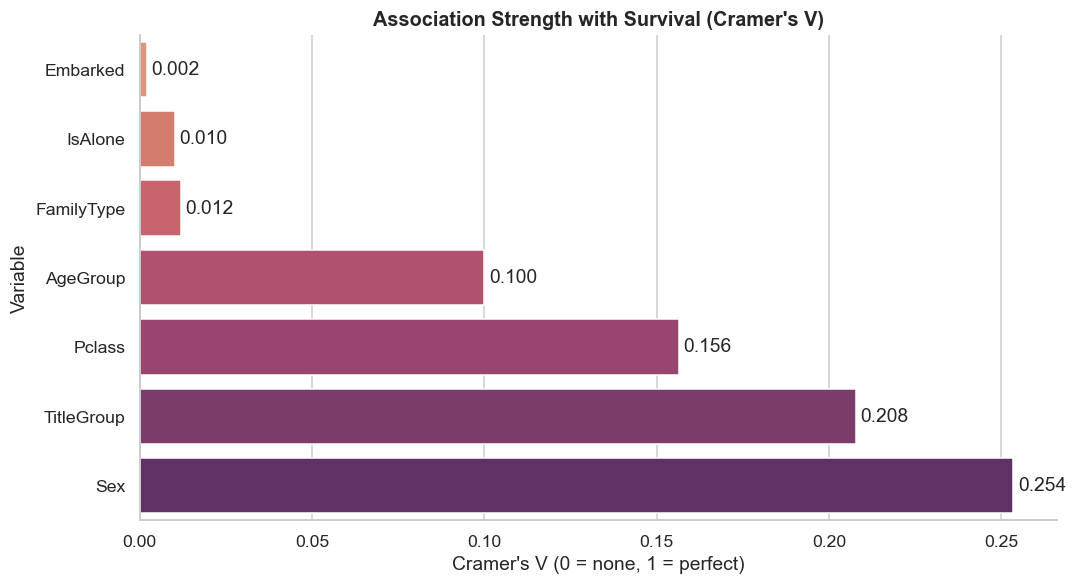

In [82]:
chi = res[res["Test"] == "Chi-square"].copy()
# p_value string aana sort ku numeric thevai
chi["p_num"] = chi["p_value"].astype(float) if chi["p_value"].dtype == object else chi["p_value"]
chi = chi.sort_values("Effect size")

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.barplot(x=chi["Effect size"], y=chi["Variable"], palette="flare", ax=ax)
for p in ax.patches:
    ax.annotate(f"{p.get_width():.3f}", (p.get_width(), p.get_y() + p.get_height() / 2), va="center", xytext=(3,0), textcoords="offset points")
ax.set_title("Association Strength with Survival (Cramer's V)")
ax.set_xlabel("Cramer's V (0 = none, 1 = perfect)")
plt.tight_layout()
plt.savefig(out / "19_effect_sizes_cramers_v.png", dpi=150)
plt.show()

In [83]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import *

RANDOM_STATE = 42
num_features = ["Age", "SibSp", "Parch", "Fare", "LogFare", "FamilySize", "IsAlone", "FarePerPerson", "AgeMissing"]
cat_features = ["Pclass", "Sex", "Embarked", "TitleGroup"]
X = d[num_features + cat_features].copy()
X["Pclass"] = X["Pclass"].astype(str)
y = d["Survived"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"Train: {X_train.shape} Test: {X_test.shape}")

Train: (80000, 13) Test: (20000, 13)


In [85]:
def make_prep(scale: bool):
    num_tf = StandardScaler() if scale else "passthrough"
    return ColumnTransformer([("num", num_tf, num_features), ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features)])

models = {
    "Logistic Regression": Pipeline([("prep", make_prep(True)), ("clf", LogisticRegression(max_iter=2000, C=1.0, random_state=RANDOM_STATE))]),
    "Random Forest": Pipeline([("prep", make_prep(False)), ("clf", RandomForestClassifier(n_estimators=250, max_depth=14, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE))]),
    "Gradient Boosting": Pipeline([("prep", make_prep(False)), ("clf", HistGradientBoostingClassifier(max_iter=300, learning_rate=0.06, max_depth=6, random_state=RANDOM_STATE))]),
}

In [86]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results, fitted, probs = [], {}, {}

for name, pipe in models.items():
    print(f"\n>>> Training {name} ...")
    cv_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    pipe.fit(X_train, y_train)
    proba = pipe.predict_proba(X_test)[:,1]
    pred = (proba >= 0.5).astype(int)
    fitted[name], probs[name] = pipe, proba
    results.append({"Model": name, "CV AUC (mean)": cv_scores.mean(), "CV AUC (std)": cv_scores.std(), "Test Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred), "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred), "Test ROC-AUC": roc_auc_score(y_test, proba), "Avg Precision": average_precision_score(y_test, proba)})
    print(f"CV AUC = {cv_scores.mean():.4f} Test Acc = {accuracy_score(y_test, pred):.4f} Test AUC = {roc_auc_score(y_test, proba):.4f}")

res = pd.DataFrame(results).set_index("Model")
print(res.round(4).to_string())
best_name = res["Test ROC-AUC"].idxmax()
print(f"\nBEST MODEL: {best_name}")
print(classification_report(y_test, (probs[best_name]>=0.5).astype(int), target_names=["Died","Survived"]))


>>> Training Logistic Regression ...
CV AUC = 0.6776 Test Acc = 0.6550 Test AUC = 0.6821

>>> Training Random Forest ...
CV AUC = 0.6734 Test Acc = 0.6520 Test AUC = 0.6771

>>> Training Gradient Boosting ...
CV AUC = 0.6784 Test Acc = 0.6549 Test AUC = 0.6829
                     CV AUC (mean)  CV AUC (std)  Test Accuracy  Precision  Recall      F1  Test ROC-AUC  Avg Precision
Model                                                                                                                  
Logistic Regression         0.6776        0.0039         0.6550     0.5976  0.3954  0.4759        0.6821         0.5773
Random Forest               0.6734        0.0041         0.6520     0.5976  0.3722  0.4587        0.6771         0.5701
Gradient Boosting           0.6784        0.0050         0.6549     0.6106  0.3561  0.4499        0.6829         0.5796

BEST MODEL: Gradient Boosting
              precision    recall  f1-score   support

        Died       0.67      0.85      0.75     1207

NameError: name 'out' is not defined

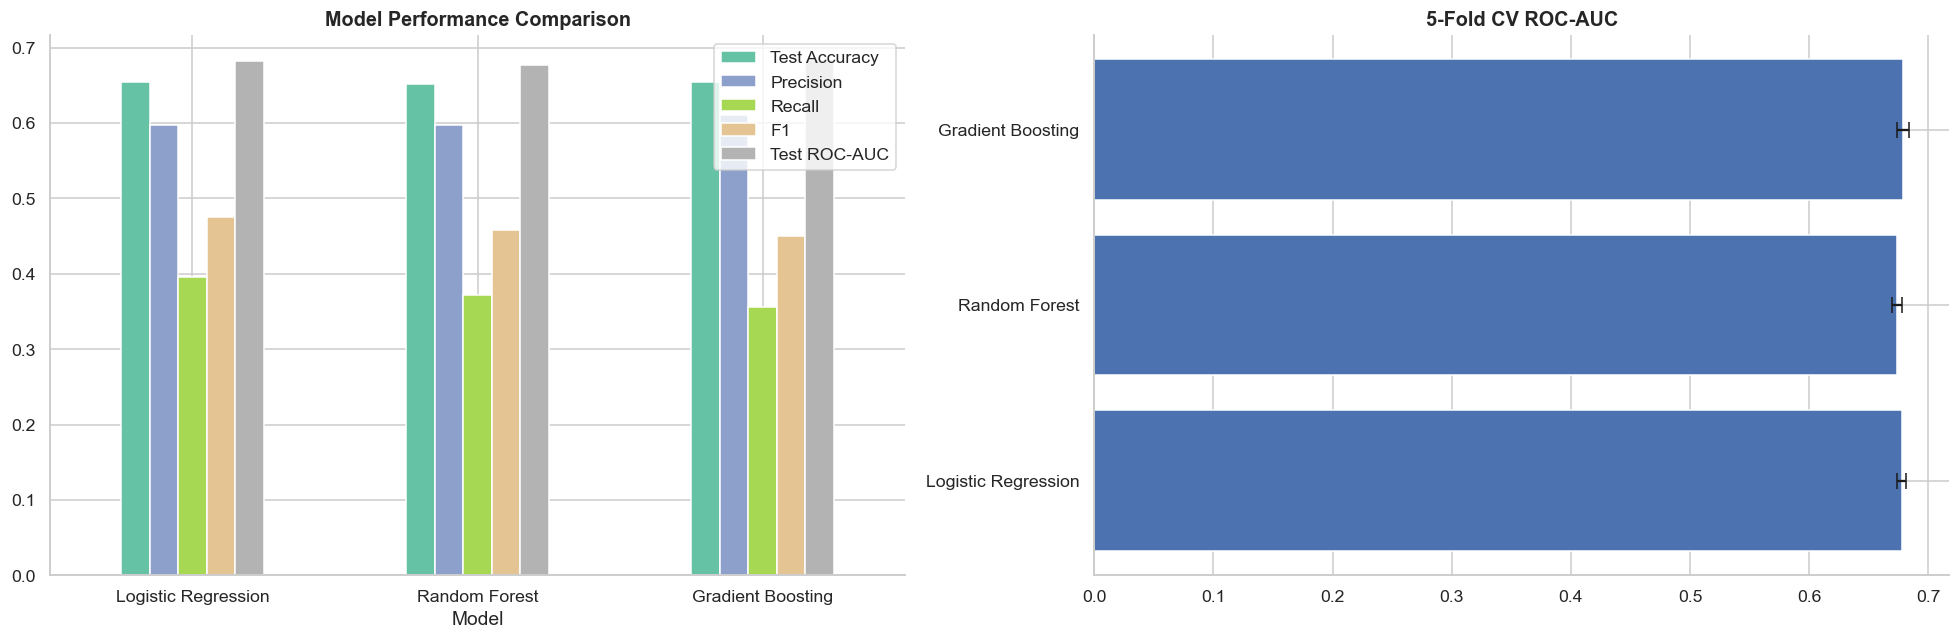

In [88]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
res[["Test Accuracy", "Precision", "Recall", "F1", "Test ROC-AUC"]].plot(kind="bar", ax=axes[0], colormap="Set2")
axes[0].set_title("Model Performance Comparison")
axes[0].tick_params(axis="x", rotation=0)
axes[1].barh(res.index, res["CV AUC (mean)"], xerr=res["CV AUC (std)"], capsize=5)
axes[1].set_title("5-Fold CV ROC-AUC")
plt.tight_layout()
plt.savefig(out / "20_model_comparison.png")
plt.show()

NameError: name 'out' is not defined

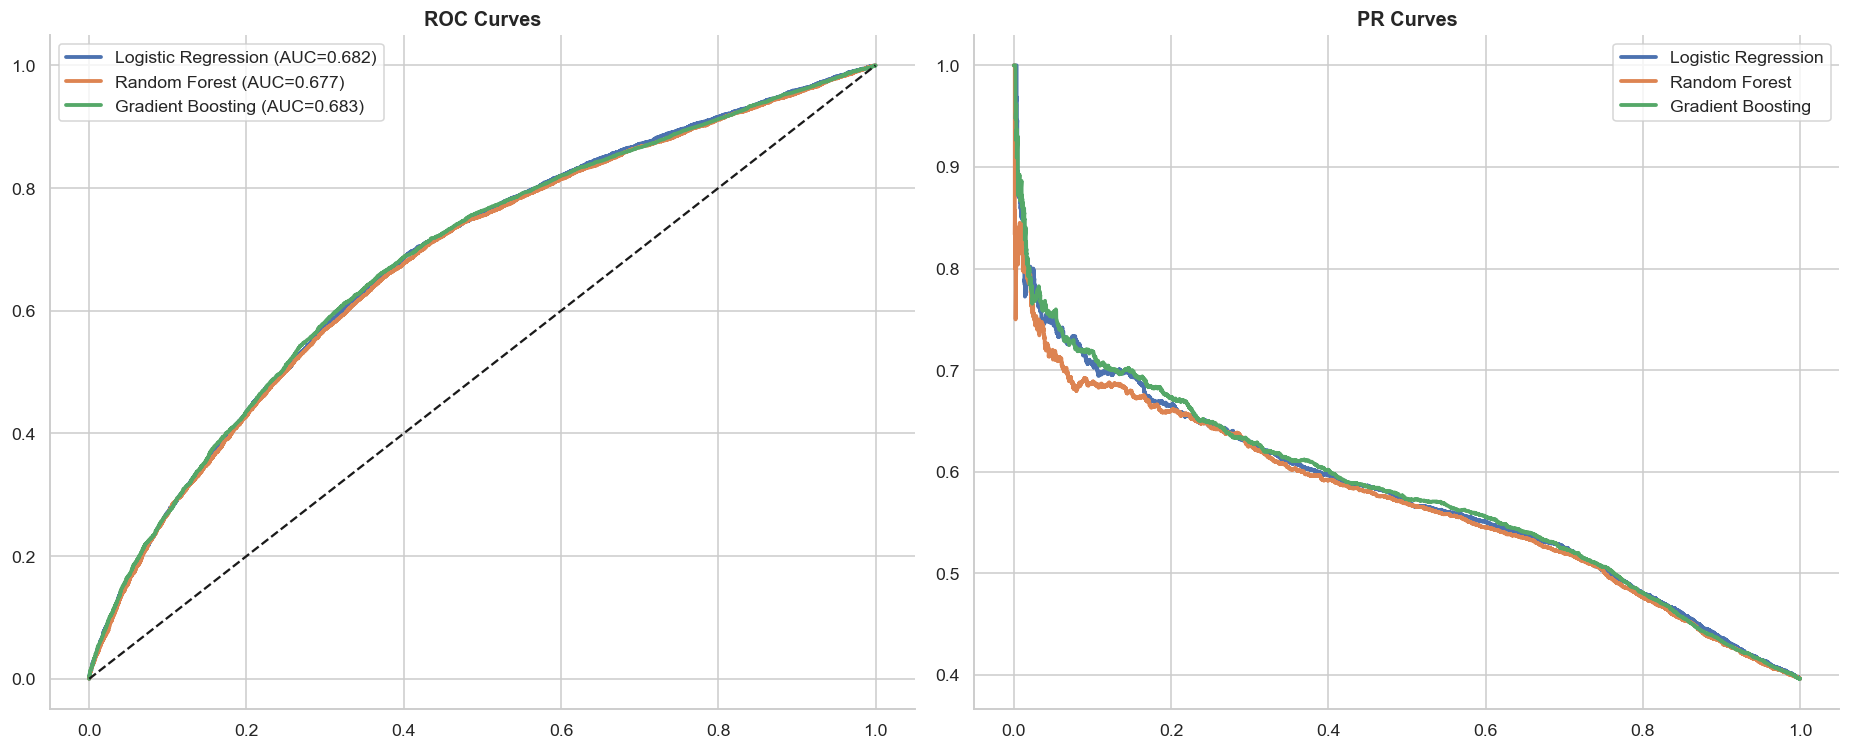

In [89]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for name, proba in probs.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, lw=2.5, label=f"{name} (AUC={auc(fpr,tpr):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(rec, prec, lw=2.5, label=f"{name}")
axes[0].plot([0,1],[0,1],"k--")
axes[0].set_title("ROC Curves")
axes[0].legend()
axes[1].set_title("PR Curves")
axes[1].legend()
plt.tight_layout()
plt.savefig(out / "21_roc_pr_curves.png")
plt.show()

NameError: name 'out' is not defined

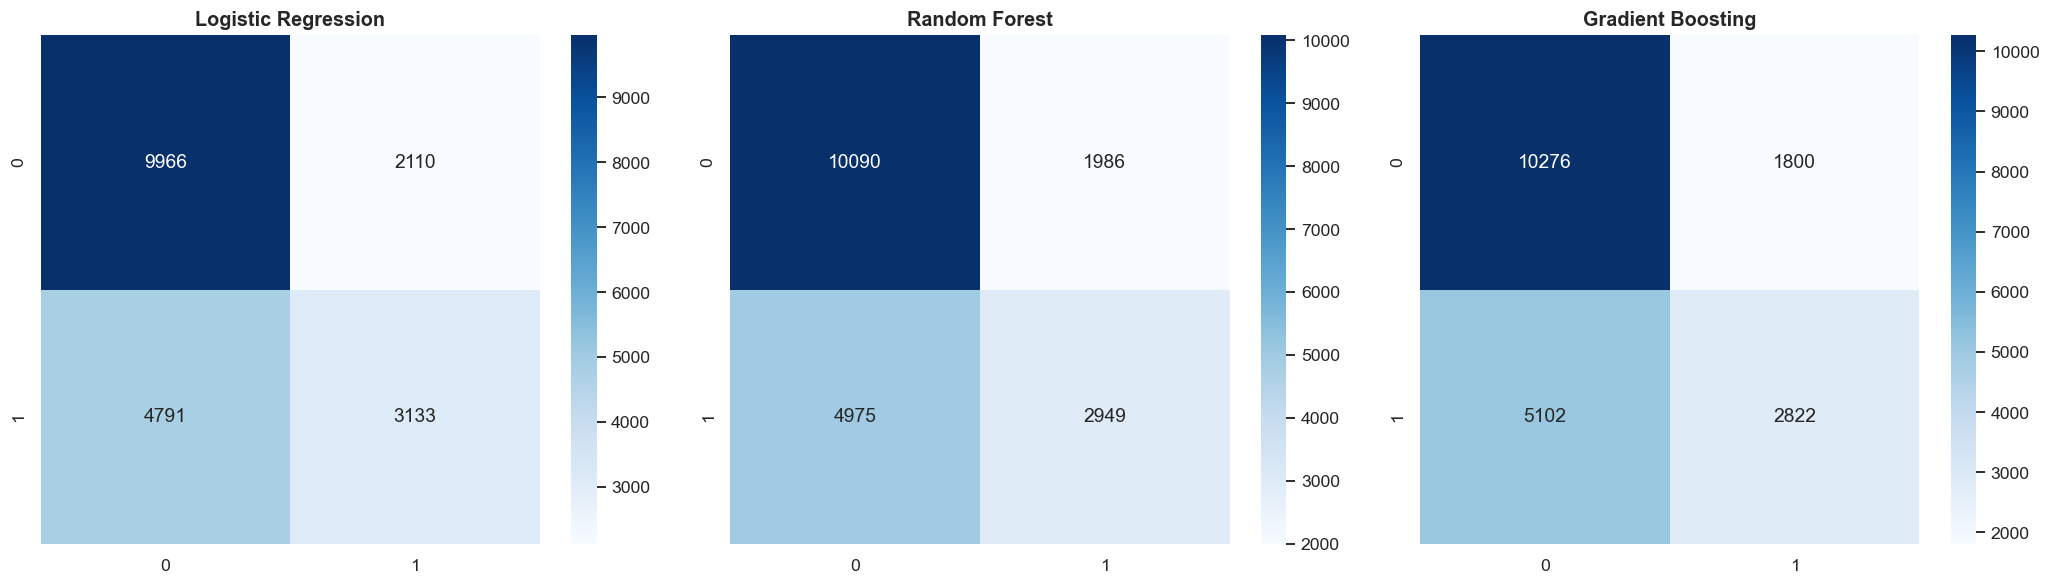

In [90]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
for ax, (name, proba) in zip(axes, probs.items()):
    cm = confusion_matrix(y_test, (proba>=0.5).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.savefig(out / "22_confusion_matrices.png")
plt.show()

NameError: name 'out' is not defined

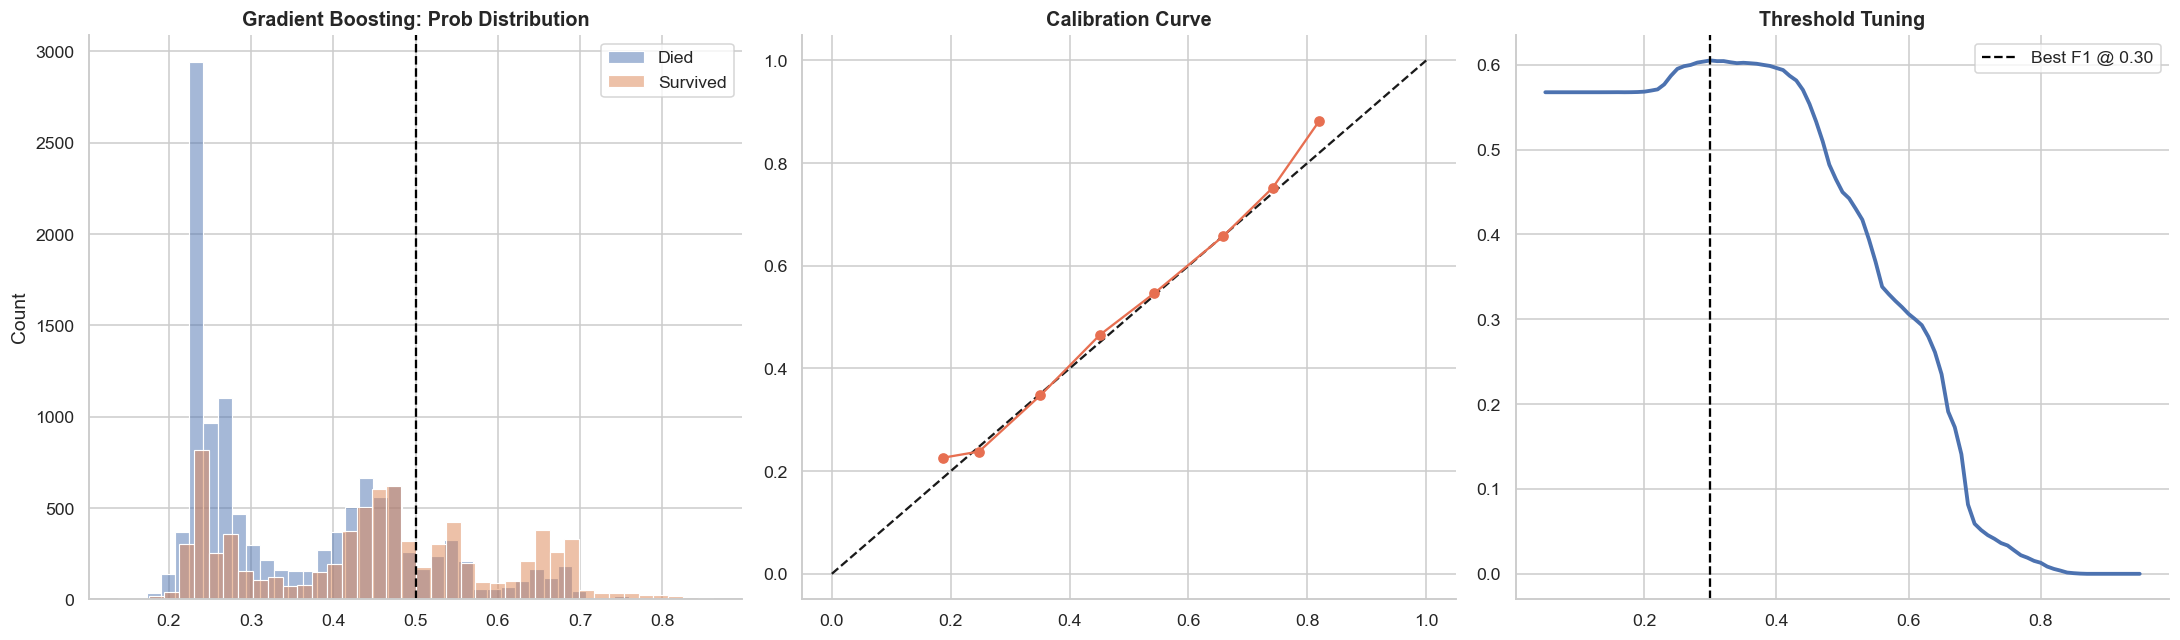

In [91]:
proba = probs[best_name]
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for outcome, val in [("Died",0), ("Survived",1)]:
    sns.histplot(proba[y_test.values==val], bins=40, alpha=0.5, label=outcome, ax=axes[0])
axes[0].axvline(0.5, color="black", ls="--")
axes[0].set_title(f"{best_name}: Prob Distribution")
axes[0].legend()

bins = np.linspace(0,1,11)
idx = np.digitize(proba, bins)-1
cal = pd.DataFrame({"bin":idx, "p":proba, "y":y_test.values}).groupby("bin").agg(mean_pred=("p","mean"), frac_pos=("y","mean"))
axes[1].plot([0,1],[0,1],"k--")
axes[1].plot(cal["mean_pred"], cal["frac_pos"], "o-", color="#E76F51")
axes[1].set_title("Calibration Curve")

thr = np.linspace(0.05,0.95,91)
f1s = [f1_score(y_test, (proba>=t).astype(int)) for t in thr]
best_t = thr[int(np.argmax(f1s))]
axes[2].plot(thr, f1s, lw=2.5)
axes[2].axvline(best_t, color="black", ls="--", label=f"Best F1 @ {best_t:.2f}")
axes[2].set_title("Threshold Tuning")
axes[2].legend()
plt.tight_layout()
plt.savefig(out / "23_probability_calibration_threshold.png")
plt.show()
print(f"Best F1 threshold: {best_t:.2f}")

In [92]:
from sklearn.inspection import permutation_importance

rf = fitted["Random Forest"]
names = rf.named_steps["prep"].get_feature_names_out()
names = [n.split("__")[1] for n in names]
imp = pd.Series(rf.named_steps["clf"].feature_importances_, index=names).sort_values(ascending=False)
print("--- Random Forest importance (top 12) ---")
print(imp.head(12).round(4).to_string())

--- Random Forest importance (top 12) ---
Age                0.1437
Sex_male           0.1327
Sex_female         0.1327
LogFare            0.1202
Fare               0.1165
FarePerPerson      0.1164
Pclass_1           0.0499
TitleGroup_Miss    0.0344
Pclass_3           0.0234
SibSp              0.0166
FamilySize         0.0158
Parch              0.0144


In [93]:
sample_idx = X_test.sample(min(8000, len(X_test)), random_state=RANDOM_STATE).index
gb = fitted["Gradient Boosting"]
perm = permutation_importance(gb, X_test.loc[sample_idx], y_test.loc[sample_idx],
                              n_repeats=8, scoring="roc_auc",
                              random_state=RANDOM_STATE, n_jobs=-1)
perm_df = pd.DataFrame({"mean": perm.importances_mean, "std": perm.importances_std},
                       index=X_test.columns).sort_values("mean", ascending=False)
print("--- Permutation importance, GB (AUC drop) ---")
print(perm_df.round(4).to_string())

--- Permutation importance, GB (AUC drop) ---
                 mean     std
Sex            0.1178  0.0055
Pclass         0.0427  0.0021
Age            0.0148  0.0013
FarePerPerson  0.0038  0.0011
Fare           0.0021  0.0008
Parch          0.0018  0.0006
SibSp          0.0017  0.0006
TitleGroup     0.0002  0.0002
AgeMissing     0.0001  0.0001
Embarked       0.0000  0.0001
LogFare        0.0000  0.0000
IsAlone       -0.0000  0.0000
FamilySize    -0.0000  0.0001


In [94]:
lr = fitted["Logistic Regression"]
lr_names = [n.split("__")[1] for n in lr.named_steps["prep"].get_feature_names_out()]
coefs = pd.Series(lr.named_steps["clf"].coef_[0], index=lr_names).sort_values()
odds = np.exp(coefs).round(3)
print("--- Logistic odds ratios ---")
print(pd.concat([odds.head(8), odds.tail(8)]).to_string())
print("\nCoef:")
print(coefs.round(4).to_string())

--- Logistic odds ratios ---
Sex_male             0.543
Pclass_3             0.658
Age                  0.845
Pclass_2             0.873
TitleGroup_Mrs       0.934
SibSp                0.943
AgeMissing           0.952
TitleGroup_Miss      0.958
TitleGroup_Rare      0.999
LogFare              1.001
TitleGroup_Master    1.002
FarePerPerson        1.012
TitleGroup_Mr        1.021
Parch                1.050
Pclass_1             1.592
Sex_female           1.684

Coef:
Sex_male            -0.6108
Pclass_3            -0.4184
Age                 -0.1683
Pclass_2            -0.1359
TitleGroup_Mrs      -0.0686
SibSp               -0.0582
AgeMissing          -0.0487
TitleGroup_Miss     -0.0434
Embarked_Q          -0.0422
Embarked_S          -0.0237
Embarked_C          -0.0235
FamilySize          -0.0144
Fare                -0.0063
IsAlone             -0.0011
TitleGroup_Rare     -0.0005
LogFare              0.0012
TitleGroup_Master    0.0025
FarePerPerson        0.0119
TitleGroup_Mr        0.0207


NameError: name 'out' is not defined

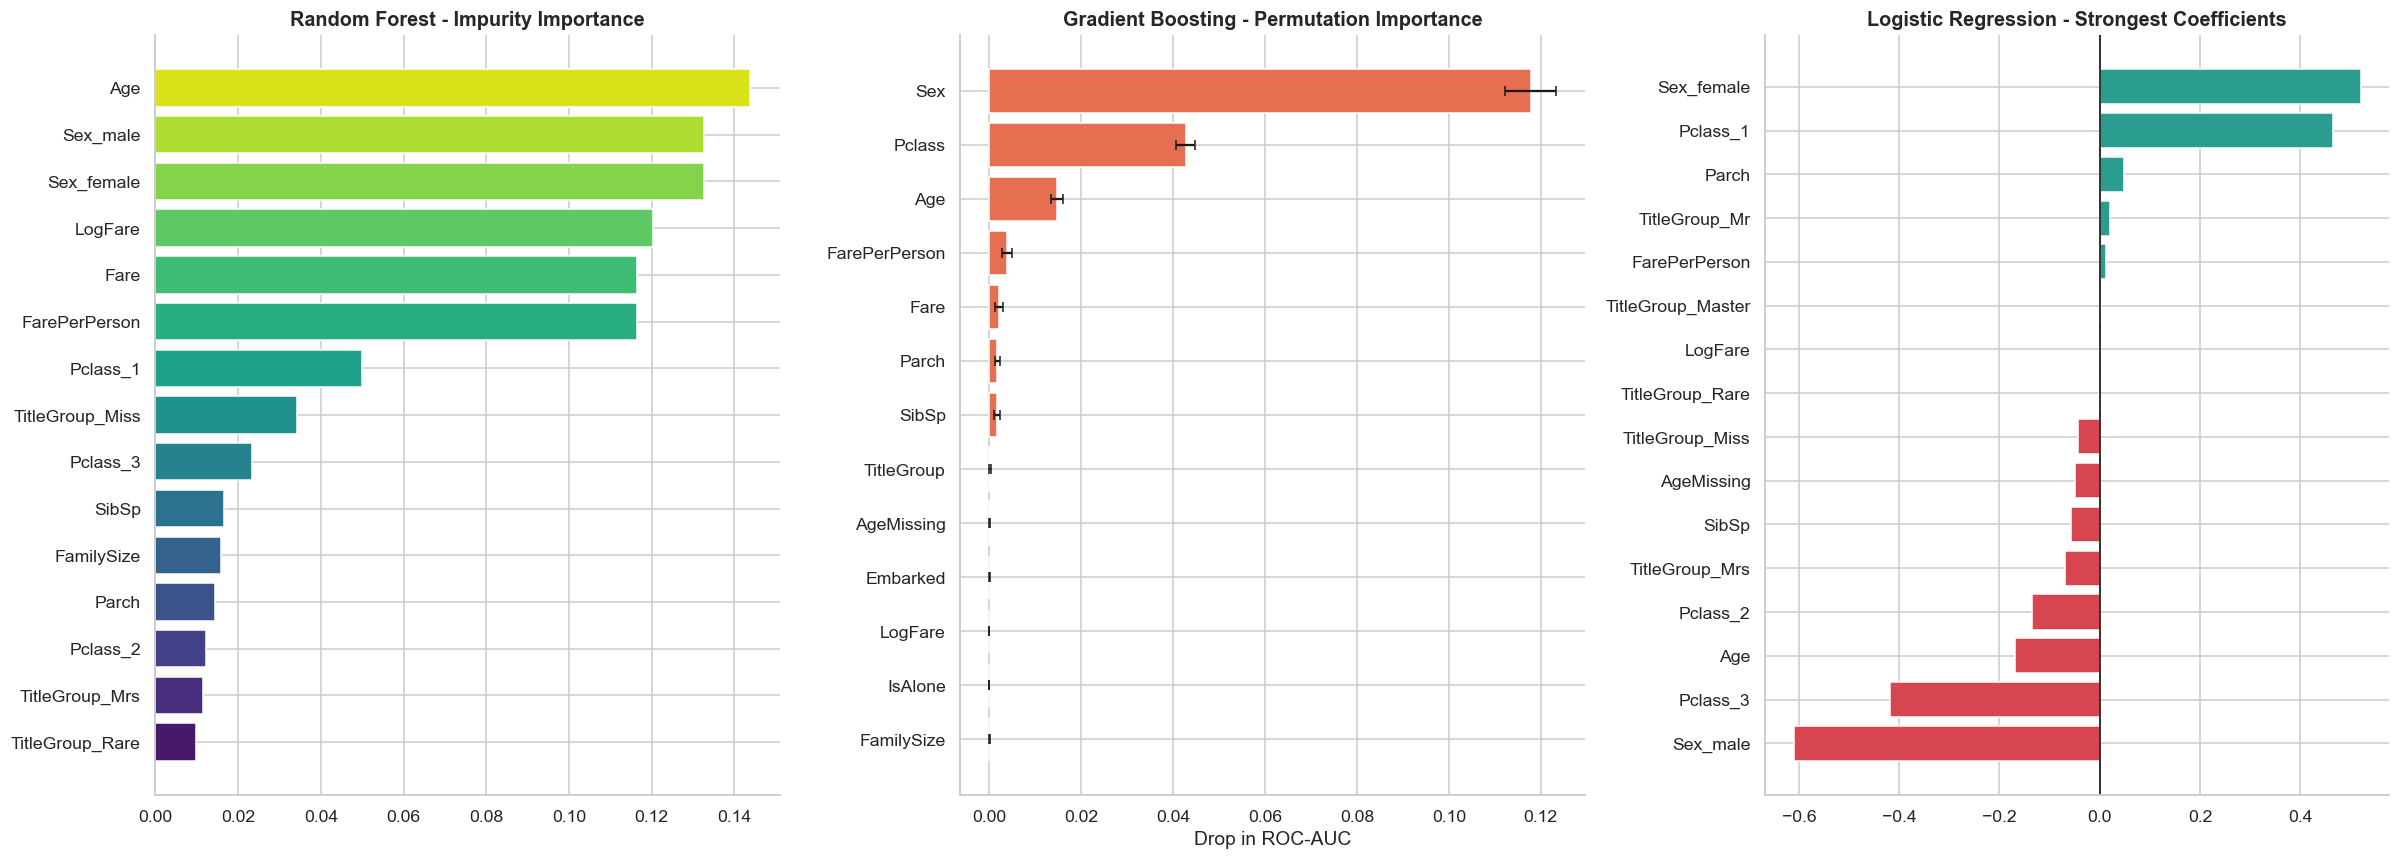

In [95]:
fig, axes = plt.subplots(1, 3, figsize=(22, 8))

top = imp.head(15)[::-1]
axes[0].barh(top.index, top.values, color=sns.color_palette("viridis", len(top)))
axes[0].set_title("Random Forest - Impurity Importance")

p = perm_df.iloc[::-1]
axes[1].barh(p.index, p["mean"], xerr=p["std"], color="#E76F51", capsize=3)
axes[1].set_title("Gradient Boosting - Permutation Importance")
axes[1].set_xlabel("Drop in ROC-AUC")

c = coefs.iloc[list(range(8)) + list(range(-8, 0))]
axes[2].barh(c.index, c.values, color=["#D64550" if v < 0 else "#2A9D8F" for v in c.values])
axes[2].axvline(0, color="black", lw=1)
axes[2].set_title("Logistic Regression - Strongest Coefficients")

plt.tight_layout()
plt.savefig(out / "24_feature_importance.png", dpi=150)
plt.show()